# we are trying to get this model to work for CAGE

for this we need to first train on CAGE (done). Then we need to train on RNA bulk and multiome

I have RNA bulk data, let's analyze it and start training

In [1]:
#we got the RNA tsv counts from ENCODE, TPM should be ok?
#we will make a json file that is gene id to TPM value for each gene

import json
import pandas as pd

tsv_file = "/data1/lesliec/sarthak/data/DK_zarr/raw_files/ENCFF501IXI.tsv"
# Read the TSV file into a DataFrame
df = pd.read_csv(tsv_file, sep='\t')
df

,gene_id,transcript_id(s),length,effective_length,expected_count,TPM,FPKM,posterior_mean_count,posterior_standard_deviation_of_count,pme_TPM,pme_FPKM,TPM_ci_lower_bound,TPM_ci_upper_bound,TPM_coefficient_of_quartile_variation,FPKM_ci_lower_bound,FPKM_ci_upper_bound,FPKM_coefficient_of_quartile_variation
0,10904,10904,93.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.00000,0.000000
1,12954,12954,94.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.00000,0.000000
2,12956,12956,72.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.00000,0.000000
3,12958,12958,82.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.00000,0.000000
4,12960,12960,73.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.00000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59521,gSpikein_ERCC-00165,tSpikein_ERCC-00165,872.0,666.74,0.0,0.00,0.00,0.0,0.0,0.03,0.02,1.203450e-06,0.094644,0.657359,9.155640e-07,0.07201,0.657283
59522,gSpikein_ERCC-00168,tSpikein_ERCC-00168,1024.0,818.73,0.0,0.00,0.00,0.0,0.0,0.03,0.02,6.138790e-07,0.078402,0.656770,4.674370e-07,0.05967,0.656924
59523,gSpikein_ERCC-00170,tSpikein_ERCC-00170,1023.0,817.73,78.0,2.08,1.55,78.0,0.0,2.06,1.56,1.610760e+00,2.513370,0.076032,1.225020e+00,1.91222,0.076022
59524,gSpikein_ERCC-00171,tSpikein_ERCC-00171,505.0,299.90,134.0,9.74,7.25,134.0,0.0,9.58,7.28,7.961480e+00,11.205000,0.058407,6.047120e+00,8.51472,0.058402


In [3]:
#clean it and resest indexixng
df_clean = df[df['gene_id'].str.startswith('ENSG')].reset_index(drop=True)
df_clean

,gene_id,transcript_id(s),length,effective_length,expected_count,TPM,FPKM,posterior_mean_count,posterior_standard_deviation_of_count,pme_TPM,pme_FPKM,TPM_ci_lower_bound,TPM_ci_upper_bound,TPM_coefficient_of_quartile_variation,FPKM_ci_lower_bound,FPKM_ci_upper_bound,FPKM_coefficient_of_quartile_variation
0,ENSG00000000003.14,"ENST00000373020.8,ENST00000494424.1,ENST000004...",1830.37,1625.10,31.00,0.42,0.31,31.00,0.00,0.52,0.40,3.322150e-01,0.739052,0.136655,2.525850e-01,0.562047,0.136706
1,ENSG00000000005.5,"ENST00000373031.4,ENST00000485971.1",940.50,735.30,0.00,0.00,0.00,0.00,0.00,0.08,0.06,6.645810e-04,0.212329,0.512376,5.351620e-04,0.161614,0.512274
2,ENSG00000000419.12,"ENST00000371582.8,ENST00000371584.8,ENST000003...",855.30,650.07,988.00,33.15,24.67,988.00,0.00,32.45,24.68,3.004530e+01,34.822100,0.025147,2.287930e+01,26.514400,0.025190
3,ENSG00000000457.13,"ENST00000367770.5,ENST00000367771.10,ENST00000...",2940.58,2735.31,1284.00,10.24,7.62,1284.00,0.00,10.06,7.65,9.360810e+00,10.759900,0.023995,7.128250e+00,8.193000,0.023973
4,ENSG00000000460.16,"ENST00000286031.10,ENST00000359326.8,ENST00000...",2529.74,2324.48,4476.00,42.00,31.25,4476.00,0.00,41.20,31.34,3.935450e+01,43.105600,0.015609,2.995740e+01,32.810500,0.015613
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58775,ENSG00000285990.1,ENST00000649331.1,647.00,441.81,0.00,0.00,0.00,0.39,0.72,0.07,0.05,1.208110e-06,0.201152,0.655396,9.192000e-07,0.153009,0.655373
58776,ENSG00000285991.1,ENST00000647612.1,5065.00,4859.73,20.11,0.09,0.07,22.21,6.55,0.10,0.08,4.005110e-02,0.173777,0.237603,3.048940e-02,0.132230,0.237644
58777,ENSG00000285992.1,ENST00000648949.1,956.00,750.73,0.00,0.00,0.00,0.00,0.00,0.03,0.02,5.833070e-08,0.084279,0.652981,3.089400e-07,0.064139,0.653007
58778,ENSG00000285993.1,ENST00000650266.1,1246.00,1040.73,0.00,0.00,0.00,0.00,0.00,0.02,0.02,1.782340e-07,0.061245,0.659733,1.355930e-07,0.046610,0.659869


In [4]:
#see if gene id is unique
print(df_clean['gene_id'].is_unique)
#so they compile the transcript_ids together I guess is nice!

True


In [6]:
TPM_vals = df_clean['TPM'].to_numpy()

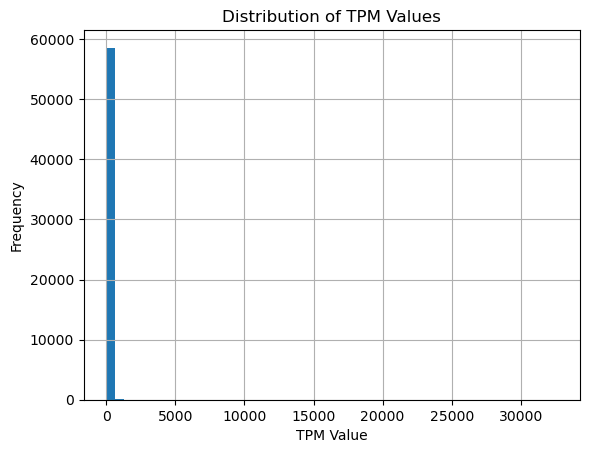

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(TPM_vals, bins=50)
plt.xlabel('TPM Value')
plt.ylabel('Frequency')
plt.title('Distribution of TPM Values')
plt.grid(True)

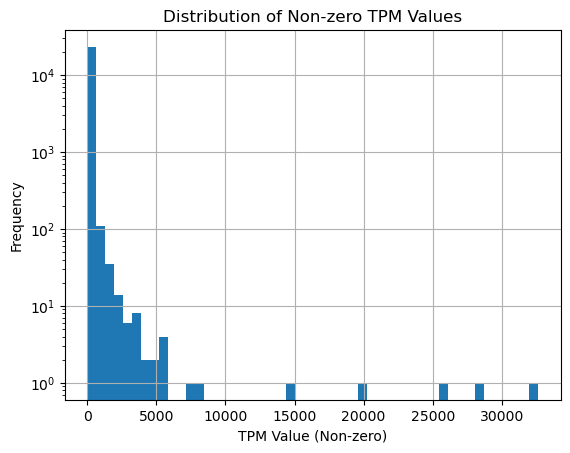

In [12]:
#the vast majority are 0, let's do just the nonzero values
nonzero_TPM = TPM_vals[TPM_vals > 0]
plt.hist(nonzero_TPM, bins=50)
plt.xlabel('TPM Value (Non-zero)')
plt.ylabel('Frequency')
plt.title('Distribution of Non-zero TPM Values')
plt.grid(True)
#and make y axis log scale
plt.yscale('log')

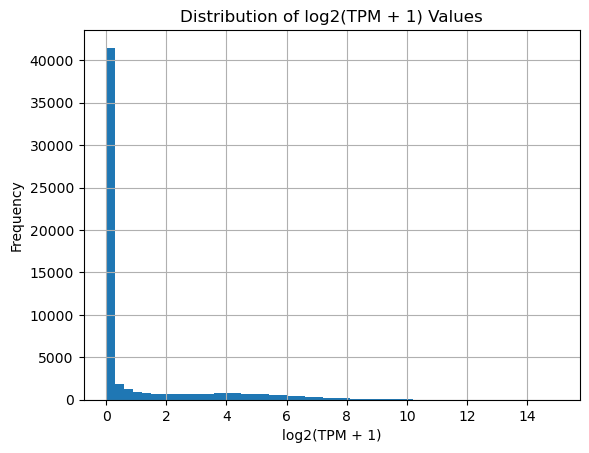

In [13]:
#what we will actually be looking at is log2(tpm+1)
log2_TPM = np.log2(TPM_vals + 1)
plt.hist(log2_TPM, bins=50)
plt.xlabel('log2(TPM + 1)')
plt.ylabel('Frequency')
plt.title('Distribution of log2(TPM + 1) Values')
plt.grid(True)

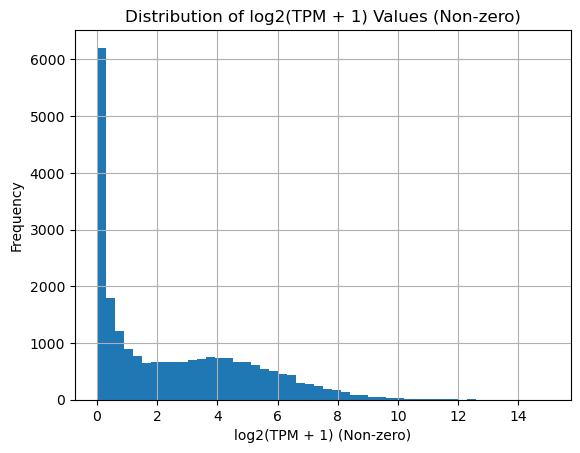

In [14]:
#again looka t values more than 0
log2_nonzero_TPM = np.log2(nonzero_TPM + 1)
plt.hist(log2_nonzero_TPM, bins=50)
plt.xlabel('log2(TPM + 1) (Non-zero)')
plt.ylabel('Frequency')
plt.title('Distribution of log2(TPM + 1) Values (Non-zero)')
plt.grid(True)

# creating the data

so we need a JSON which per gene will have a dict that 'counts' gives log2(TPM+1) and 'tss' gives the TSS location (we can do midpoint of the 500 bp region they give us)

we will also include locations of alternate TSS as well, so need to go through each gene (we can do just unique genes and filter, but that will be slow), then get information from both dfs

For downstream stuff, look at EP_linking

In [22]:
#so it's this file
import pandas as pd
TSS_bounds_file = "/data1/deyk/extras/CollapsedGeneBounds.hg38.TSS500bp.bed"
tss = pd.read_csv(TSS_bounds_file, sep='\t')
tss

,#chr,start,end,name,score,strand,Ensembl_ID,gene_type
0,chr1,35831,36331,FAM138A,0,-,ENSG00000237613,lincRNA
1,chr1,35831,36331,FAM138F,0,-,ENSG00000282591,lincRNA
2,chr1,68840,69340,OR4F5,0,+,ENSG00000186092,protein_coding
3,chr1,817120,817620,FAM87B,0,+,ENSG00000177757,lincRNA
4,chr1,827272,827772,LINC00115,0,-,ENSG00000225880,lincRNA
...,...,...,...,...,...,...,...,...
20662,chrY,21386110,21386610,PRORY,0,-,ENSG00000183146,protein_coding
20663,chrY,21594416,21594916,TTTY13,0,-,ENSG00000184991,lincRNA
20664,chrY,22298626,22299126,TTTY5,0,-,ENSG00000215560,lincRNA
20665,chrY,23198842,23199342,DAZ1,0,-,ENSG00000188120,protein_coding


In [23]:
#it has all the genes which is good! But we should subset to protein coding?
tss['gene_type'].value_counts() #

gene_type
protein_coding          18943
lincRNA                  1496
processed_transcript      199
TEC                        14
sense_overlapping          13
non_coding                  1
IG_V_gene                   1
Name: count, dtype: int64

In [25]:
#so now we want to create this JSON file, first we need to load gencode info
import re

gtf_path = "/data1/lesliec/sarthak/data/DE_danwei/gencode.v49.annotation.gtf"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chrom", "source", "feature",
        "start", "end", "score",
        "strand", "frame", "attribute"
    ],
)

def get_attr(attr_str, key):
    m = re.search(fr'{key} "([^"]+)"', attr_str)
    return m.group(1) if m else None

for key in ["gene_id", "transcript_id", "gene_type", "gene_name", "transcript_type"]:
    gtf[key] = gtf["attribute"].apply(lambda s, k=key: get_attr(s, k))

gtf_coding = gtf[gtf['gene_type'] == 'protein_coding']
gtf_coding

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
2486,chr1,HAVANA,gene,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; gene_type ""protei...",ENSG00000186092.7,None,protein_coding,OR4F5,None
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2488,chr1,HAVANA,exon,65419,65433,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2489,chr1,HAVANA,exon,65520,65573,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2490,chr1,HAVANA,CDS,65565,65573,.,+,0,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750143,chrM,ENSEMBL,gene,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; gene_type ""protei...",ENSG00000198727.2,None,protein_coding,MT-CYB,None
7750144,chrM,ENSEMBL,transcript,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750145,chrM,ENSEMBL,exon,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750146,chrM,ENSEMBL,CDS,14747,15887,.,+,0,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding


In [45]:
#so now do a large loop to create this major dict
import pandas as pd
import numpy as np

# 1. Process 'counts' from df_clean
# Log transform TPM and map gene_id to the new count
df_clean['counts'] = np.log2(df_clean['TPM'] + 1)
counts_dict = df_clean.set_index('gene_id')['counts'].to_dict()
counts_dict

{'ENSG00000000003.14': 0.5058909297299573,
 'ENSG00000000005.5': 0.0,
 'ENSG00000000419.12': 5.093813673402728,
 'ENSG00000000457.13': 3.4905701304462013,
 'ENSG00000000460.16': 5.426264754702098,
 'ENSG00000000938.12': 0.028569152196770916,
 'ENSG00000000971.15': 6.453188309548226,
 'ENSG00000001036.13': 4.705425039042727,
 'ENSG00000001084.12': 3.5582676340557358,
 'ENSG00000001167.14': 4.57228336665041,
 'ENSG00000001460.17': 2.6758159311722696,
 'ENSG00000001461.16': 3.493134922305505,
 'ENSG00000001497.16': 6.589913260672201,
 'ENSG00000001561.6': 0.0,
 'ENSG00000001617.11': 3.232660756790275,
 'ENSG00000001626.15': 0.0,
 'ENSG00000001629.9': 5.381283372503783,
 'ENSG00000001630.16': 3.063502942306158,
 'ENSG00000001631.15': 5.323370069061268,
 'ENSG00000002016.17': 5.506843098969815,
 'ENSG00000002079.14': 0.25096157353321874,
 'ENSG00000002330.13': 3.1602748314085933,
 'ENSG00000002549.12': 4.461397589926158,
 'ENSG00000002586.19': 4.479618608469416,
 'ENSG00000002586.19_PAR_Y':

In [31]:
# 2. Process 'tss' from the tss dataframe
# Add 250 to start and map Ensembl_ID to the new tss
tss['main_tss'] = tss['start'] + 250
tss_dict = tss.set_index('Ensembl_ID')['main_tss'].to_dict()
# tss_dict

# 3. Process 'alt_tss' from gtf_coding
# Filter for transcripts to avoid redundant exon/CDS rows
tx_df = gtf_coding[(gtf_coding['feature'] == 'transcript') & 
                   (gtf_coding['transcript_type'] == 'protein_coding')].copy()
tx_df

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
6558,chr1,HAVANA,transcript,450740,451678,.,-,.,"gene_id ""ENSG00000284733.2""; transcript_id ""EN...",ENSG00000284733.2,ENST00000426406.4,protein_coding,OR4F29,protein_coding
7173,chr1,HAVANA,transcript,685716,686654,.,-,.,"gene_id ""ENSG00000284662.2""; transcript_id ""EN...",ENSG00000284662.2,ENST00000332831.5,protein_coding,OR4F16,protein_coding
8431,chr1,HAVANA,transcript,923923,944572,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000968544.1,protein_coding,SAMD11,protein_coding
8464,chr1,HAVANA,transcript,923923,944574,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000616016.5,protein_coding,SAMD11,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750109,chrM,ENSEMBL,transcript,10470,10766,.,+,.,"gene_id ""ENSG00000212907.2""; transcript_id ""EN...",ENSG00000212907.2,ENST00000361335.1,protein_coding,MT-ND4L,protein_coding
7750116,chrM,ENSEMBL,transcript,10760,12137,.,+,.,"gene_id ""ENSG00000198886.2""; transcript_id ""EN...",ENSG00000198886.2,ENST00000361381.2,protein_coding,MT-ND4,protein_coding
7750130,chrM,ENSEMBL,transcript,12337,14148,.,+,.,"gene_id ""ENSG00000198786.2""; transcript_id ""EN...",ENSG00000198786.2,ENST00000361567.2,protein_coding,MT-ND5,protein_coding
7750136,chrM,ENSEMBL,transcript,14149,14673,.,-,.,"gene_id ""ENSG00000198695.2""; transcript_id ""EN...",ENSG00000198695.2,ENST00000361681.2,protein_coding,MT-ND6,protein_coding


In [32]:
tx_df['calc_tss'] = np.where(tx_df['strand'] == '+', tx_df['start'], tx_df['end']) #on plus strand, TSS is start, on minus strand, TSS is end
tx_df

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type,calc_tss
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding,65419
6558,chr1,HAVANA,transcript,450740,451678,.,-,.,"gene_id ""ENSG00000284733.2""; transcript_id ""EN...",ENSG00000284733.2,ENST00000426406.4,protein_coding,OR4F29,protein_coding,451678
7173,chr1,HAVANA,transcript,685716,686654,.,-,.,"gene_id ""ENSG00000284662.2""; transcript_id ""EN...",ENSG00000284662.2,ENST00000332831.5,protein_coding,OR4F16,protein_coding,686654
8431,chr1,HAVANA,transcript,923923,944572,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000968544.1,protein_coding,SAMD11,protein_coding,923923
8464,chr1,HAVANA,transcript,923923,944574,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000616016.5,protein_coding,SAMD11,protein_coding,923923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750109,chrM,ENSEMBL,transcript,10470,10766,.,+,.,"gene_id ""ENSG00000212907.2""; transcript_id ""EN...",ENSG00000212907.2,ENST00000361335.1,protein_coding,MT-ND4L,protein_coding,10470
7750116,chrM,ENSEMBL,transcript,10760,12137,.,+,.,"gene_id ""ENSG00000198886.2""; transcript_id ""EN...",ENSG00000198886.2,ENST00000361381.2,protein_coding,MT-ND4,protein_coding,10760
7750130,chrM,ENSEMBL,transcript,12337,14148,.,+,.,"gene_id ""ENSG00000198786.2""; transcript_id ""EN...",ENSG00000198786.2,ENST00000361567.2,protein_coding,MT-ND5,protein_coding,12337
7750136,chrM,ENSEMBL,transcript,14149,14673,.,-,.,"gene_id ""ENSG00000198695.2""; transcript_id ""EN...",ENSG00000198695.2,ENST00000361681.2,protein_coding,MT-ND6,protein_coding,14673


In [33]:
alt_tss_dict = tx_df.groupby('gene_id')['calc_tss'].apply(lambda x: list(set(x))).to_dict()

alt_tss_dict

{'ENSG00000000003.17': [100636739,
  100636806,
  100636782,
  100637104,
  100636752,
  100636762,
  100636829],
 'ENSG00000000005.6': [100584936],
 'ENSG00000000419.15': [50958531, 50959140, 50958532, 50958533, 50958555],
 'ENSG00000000457.15': [169893987,
  169893926,
  169893511,
  169893896,
  169893959,
  169893928,
  169893998,
  169893909,
  169893687,
  169888888,
  169893657,
  169894267],
 'ENSG00000000460.18': [169795040,
  169795043,
  169795045,
  169745574,
  169794730,
  169745548,
  169795056,
  169745489,
  169795088,
  169795091,
  169795409,
  169794709,
  169794678,
  169794999,
  169795921,
  169795065],
 'ENSG00000000938.14': [27626240,
  27625346,
  27628932,
  27627396,
  27635213,
  27626135,
  27634585,
  27626029,
  27625262,
  27635120,
  27635134,
  27626562,
  27626565,
  27626569,
  27626187,
  27635285,
  27626494,
  27628886,
  27634525,
  27635165,
  27626091,
  27635180,
  27635565,
  27635182,
  27635185,
  27635191,
  27626236,
  27624062],
 'ENSG0

In [41]:
#manually verify some of these
temp_df = gtf_coding[gtf_coding['gene_id'] == 'ENSG00000000457.15']
temp_df[temp_df['feature'] == 'transcript'] #so it has many transcripts, and the TSS for those are 2 of the values in the list, so looks good!

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
579908,chr1,HAVANA,transcript,169846981,169893909,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000910083.1,protein_coding,SCYL3,protein_coding
579941,chr1,HAVANA,transcript,169849631,169893896,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000367771.11,protein_coding,SCYL3,protein_coding
579972,chr1,HAVANA,transcript,169853074,169888888,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000367770.5,protein_coding,SCYL3,protein_coding
580003,chr1,HAVANA,transcript,169853074,169893511,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000910088.1,protein_coding,SCYL3,protein_coding
580036,chr1,HAVANA,transcript,169853074,169893687,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000910086.1,protein_coding,SCYL3,protein_coding
580067,chr1,ENSEMBL,transcript,169853074,169893959,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000367772.8,protein_coding,SCYL3,protein_coding
580100,chr1,HAVANA,transcript,169853084,169893928,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000910085.1,protein_coding,SCYL3,protein_coding
580131,chr1,HAVANA,transcript,169853089,169893998,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000937694.1,protein_coding,SCYL3,protein_coding
580162,chr1,HAVANA,transcript,169853091,169893926,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000966135.1,protein_coding,SCYL3,protein_coding
580195,chr1,HAVANA,transcript,169853093,169893657,.,-,.,"gene_id ""ENSG00000000457.15""; transcript_id ""E...",ENSG00000000457.15,ENST00000910087.1,protein_coding,SCYL3,protein_coding


In [46]:
# 4. Combine into the final nested dictionary
final_gene_dict = {}

# Use the unique genes from your filtered GTF as the base keys
unique_genes = gtf_coding['gene_id'].dropna().unique()

for gene in unique_genes:
    # gene_id = gene.split('.')[0]  # Remove version number if present
    final_gene_dict[gene] = {
        'counts': counts_dict.get(gene, 0.0),  # Defaults to 0.0 if missing from df_clean
        'tss': tss_dict.get(gene, None),       # Defaults to None if missing
        'alt_tss': alt_tss_dict.get(gene, [])  # Defaults to empty list if missing
    }
    
final_gene_dict

{'ENSG00000186092.7': {'counts': 0.0, 'tss': None, 'alt_tss': [65419]},
 'ENSG00000284733.2': {'counts': 0.0, 'tss': None, 'alt_tss': [451678]},
 'ENSG00000284662.2': {'counts': 0.0, 'tss': None, 'alt_tss': [686654]},
 'ENSG00000187634.14': {'counts': 0.0,
  'tss': None,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 0.0,
  'tss': None,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 0.0,
  'tss': None,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 0.0,
  'tss': None,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.0,
  'tss': None,
  'alt_tss': [982112, 982117, 981

In [47]:
#let's see how manyy genes have missing counts or tss
missing_counts = sum(1 for v in final_gene_dict.values() if v['counts'] == 0.0)
missing_tss = sum(1 for v in final_gene_dict.values() if v['tss'] is None)
print(f"Number of genes with missing counts: {missing_counts}", f"Number of genes with missing tss: {missing_tss}")
#ahh it seems to be versioning issue lol. So need to redo it but remove version number from gene ids in all dicts

Number of genes with missing counts: 19623 Number of genes with missing tss: 20097


In [50]:
import pandas as pd
import numpy as np

# 1. Process 'counts' from df_clean
# Log transform TPM and map gene_id to the new count
df_clean['counts'] = np.log2(df_clean['TPM'] + 1)
df_clean['gene_id_unversioned'] = df_clean['gene_id'].str.split('.').str[0]  # Remove version number
counts_dict = df_clean.set_index('gene_id_unversioned')['counts'].to_dict()

# 2. Process 'tss' from the tss dataframe
# Add 250 to start and map Ensembl_ID to the new tss
tss['main_tss'] = tss['start'] + 250
tss['Ensembl_ID_unversioned'] = tss['Ensembl_ID'].str.split('.').str[0]  # Remove version number
tss_dict = tss.set_index('Ensembl_ID_unversioned')['main_tss'].to_dict()

# 3. Process 'alt_tss' from gtf_coding
# Filter for transcripts to avoid redundant exon/CDS rows
tx_df = gtf_coding[(gtf_coding['feature'] == 'transcript') & 
                   (gtf_coding['transcript_type'] == 'protein_coding')].copy()

# Calculate the actual TSS considering the strand
tx_df['calc_tss'] = np.where(tx_df['strand'] == '+', tx_df['start'], tx_df['end'])

# Group by gene_id, extract unique TSS values using set(), and convert to a list
alt_tss_dict = tx_df.groupby('gene_id')['calc_tss'].apply(lambda x: list(set(x))).to_dict()

# 4. Combine into the final nested dictionary
final_gene_dict = {}

# Use the unique genes from your filtered GTF as the base keys
unique_genes = gtf_coding['gene_id'].dropna().unique()

for gene in unique_genes:
    gene_id = gene.split('.')[0]  # Remove version number if present
    final_gene_dict[gene] = {
        'counts': counts_dict.get(gene_id, -1),  # Defaults to 0.0 if missing from df_clean
        'tss': tss_dict.get(gene_id, None),       # Defaults to None if missing
        'alt_tss': alt_tss_dict.get(gene, [])  # Defaults to empty list if missing
    }

In [52]:
missing_counts = sum(1 for v in final_gene_dict.values() if v['counts'] == -1)
missing_tss = sum(1 for v in final_gene_dict.values() if v['tss'] is None)
missing_alt_tss = sum(1 for v in final_gene_dict.values() if len(v['alt_tss']) == 0)
print(f"Number of genes with missing counts: {missing_counts}", f"Number of genes with missing tss: {missing_tss}", f"Number of genes with missing alt_tss: {missing_alt_tss}")
#so 351 of them were filtered out of gtf coding because they didn't have any transcripts? let's visit these ones

Number of genes with missing counts: 255 Number of genes with missing tss: 1311 Number of genes with missing alt_tss: 351


In [54]:
for v in final_gene_dict:
    if final_gene_dict[v]['alt_tss'] == []:
        print(v)
        break

ENSG00000285629.1


In [ ]:
#let's filter gtf_coding to v
gtf_coding[gtf_coding['gene_id'] == v] #ok so not real genes, that makes sense to filter them

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
48811,chr1,HAVANA,gene,6159430,6197757,.,-,.,"gene_id ""ENSG00000285629.1""; gene_type ""protei...",ENSG00000285629.1,None,protein_coding,ENSG00000285629,None
48812,chr1,HAVANA,transcript,6159430,6197757,.,-,.,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48813,chr1,HAVANA,exon,6197652,6197757,.,-,.,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48814,chr1,HAVANA,CDS,6197652,6197669,.,-,0,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48815,chr1,HAVANA,start_codon,6197667,6197669,.,-,0,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48816,chr1,HAVANA,exon,6192930,6193054,.,-,.,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48817,chr1,HAVANA,CDS,6192930,6193054,.,-,0,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48818,chr1,HAVANA,exon,6181269,6181486,.,-,.,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48819,chr1,HAVANA,CDS,6181471,6181486,.,-,1,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay
48820,chr1,HAVANA,stop_codon,6181468,6181470,.,-,0,"gene_id ""ENSG00000285629.1""; transcript_id ""EN...",ENSG00000285629.1,ENST00000484532.6,protein_coding,ENSG00000285629,nonsense_mediated_decay


In [57]:
len(final_gene_dict)

20097

In [56]:
#now let's remove all genes that have the default values for any of the categories
final_gene_dict_filtered = {k: v for k, v in final_gene_dict.items() if v['counts'] != -1 and v['tss'] is not None and len(v['alt_tss']) > 0}
len(final_gene_dict_filtered)

18745

In [ ]:
#now save this as a json file
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info_unfiltered.json', 'w') as f:
    json.dump(final_gene_dict_filtered, f)

In [ ]:
#let's load it into another dict and ensure it's equal
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info_unfiltered.json', 'r') as f:
    loaded_dict = json.load(f)

In [ ]:
loaded_dict == final_gene_dict_filtered #exactly the same!

True

# now single cell multiome data

In [2]:
#we can load in cell x gene array. Use the scooby environment for anndata
import anndata as ad
import numpy as np

# 1. Load the file (much faster and lighter than import scanpy)
adata = ad.read_h5ad("/data1/deyk/scdata/251110_igvf_k562_multiome/K562_ERR9847049_Multiome.rna.align.kb.hg38.cells_x_genes.total.h5ad")

#find the attributes of adata
print(adata.var) #genes
print(adata.obs) #cells
print(adata.X.shape) #cell x gene matrix

Empty DataFrame
Columns: []
Index: [ENSG00000290825.1, DDX11L1, WASH7P, MIR6859-1, MIR1302-2HG, MIR1302-2, FAM138A, OR4G4P, ENSG00000290826, OR4G11P, OR4F5, ENSG00000238009, ENSG00000239945, CICP27, ENSG00000268903, ENSG00000269981, ENSG00000239906, ENSG00000241860, RNU6-1100P, ENSG00000241599, DDX11L17, WASH9P, MIR6859-2, ENSG00000228463, ENSG00000286448, RPL23AP24, ENSG00000236601, ENSG00000290385, WBP1LP7, OR4F29, ENSG00000237094, CICP7, ENSG00000250575, ENSG00000278757.1, ENSG00000230021, ENSG00000235146, MTND1P23, MTND2P28, MTCO1P12, ENSG00000278791, MTCO2P12, MTATP8P1, MTATP6P1, MTCO3P12, WBP1LP6, OR4F16, CICP3, ENSG00000291215, RNU6-1199P, ENSG00000229905, ENSG00000228327, LINC01409, ENSG00000285268, ENSG00000290784, ENSG00000230092, FAM87B, LINC00115, LINC01128, ENSG00000288531, FAM41C, TUBB8P11, ENSG00000283040, ENSG00000272438, ENSG00000230699, ENSG00000241180, LINC02593, SAMD11, NOC2L, KLHL17, PLEKHN1, PERM1, ENSG00000272512, HES4, ISG15, ENSG00000231702, ENSG00000224969, AG

In [ ]:
len(adata.obs), len(adata.var) #so 700k cells and 62k genes. pretty solid I think?

(708643, 62703)

In [ ]:
#let's now load in the data and see if we have results for all the genes ideally?

import json
bulk_dict = json.load(open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info_unfiltered.json', 'r'))
bulk_dict

{'ENSG00000186092.7': {'counts': 0.0, 'tss': 69090, 'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 1.5210507369009632,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.2387868595871165,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]},
 'ENSG000001882

In [11]:
adata.var_names_noversion = adata.var_names.str.split('.').str[0] #remove version number from adata var names
adata.var_names_noversion

Index(['ENSG00000290825', 'DDX11L1', 'WASH7P', 'MIR6859-1', 'MIR1302-2HG',
       'MIR1302-2', 'FAM138A', 'OR4G4P', 'ENSG00000290826', 'OR4G11P',
       ...
       'MT-ND4', 'MT-TH', 'MT-TS2', 'MT-TL2', 'MT-ND5', 'MT-ND6', 'MT-TE',
       'MT-CYB', 'MT-TT', 'MT-TP'],
      dtype='object', length=62703)

In [12]:
#now let's loop through
not_in = 0
for gene in bulk_dict:
    gene = gene.split('.')[0] #remove version number
    if gene not in adata.var_names_noversion:
        not_in += 1
print(f"Number of genes in bulk dict not found in adata: {not_in}")

Number of genes in bulk dict not found in adata: 18713


In [ ]:
len(bulk_dict) #why'd it literally find none of them? wtf?

18745

In [14]:
adata.var_names.values

array(['ENSG00000290825.1', 'DDX11L1', 'WASH7P', ..., 'MT-CYB', 'MT-TT',
       'MT-TP'], dtype=object)

In [16]:
print(adata.var)

Empty DataFrame
Columns: []
Index: [ENSG00000290825.1, DDX11L1, WASH7P, MIR6859-1, MIR1302-2HG, MIR1302-2, FAM138A, OR4G4P, ENSG00000290826, OR4G11P, OR4F5, ENSG00000238009, ENSG00000239945, CICP27, ENSG00000268903, ENSG00000269981, ENSG00000239906, ENSG00000241860, RNU6-1100P, ENSG00000241599, DDX11L17, WASH9P, MIR6859-2, ENSG00000228463, ENSG00000286448, RPL23AP24, ENSG00000236601, ENSG00000290385, WBP1LP7, OR4F29, ENSG00000237094, CICP7, ENSG00000250575, ENSG00000278757.1, ENSG00000230021, ENSG00000235146, MTND1P23, MTND2P28, MTCO1P12, ENSG00000278791, MTCO2P12, MTATP8P1, MTATP6P1, MTCO3P12, WBP1LP6, OR4F16, CICP3, ENSG00000291215, RNU6-1199P, ENSG00000229905, ENSG00000228327, LINC01409, ENSG00000285268, ENSG00000290784, ENSG00000230092, FAM87B, LINC00115, LINC01128, ENSG00000288531, FAM41C, TUBB8P11, ENSG00000283040, ENSG00000272438, ENSG00000230699, ENSG00000241180, LINC02593, SAMD11, NOC2L, KLHL17, PLEKHN1, PERM1, ENSG00000272512, HES4, ISG15, ENSG00000231702, ENSG00000224969, AG

In [20]:
import mygene #can use mygene to convert to ENSG ids so it is at least consistent
mg = mygene.MyGeneInfo()
symbols = adata.var_names.tolist()
symbols

['ENSG00000290825.1',
 'DDX11L1',
 'WASH7P',
 'MIR6859-1',
 'MIR1302-2HG',
 'MIR1302-2',
 'FAM138A',
 'OR4G4P',
 'ENSG00000290826',
 'OR4G11P',
 'OR4F5',
 'ENSG00000238009',
 'ENSG00000239945',
 'CICP27',
 'ENSG00000268903',
 'ENSG00000269981',
 'ENSG00000239906',
 'ENSG00000241860',
 'RNU6-1100P',
 'ENSG00000241599',
 'DDX11L17',
 'WASH9P',
 'MIR6859-2',
 'ENSG00000228463',
 'ENSG00000286448',
 'RPL23AP24',
 'ENSG00000236601',
 'ENSG00000290385',
 'WBP1LP7',
 'OR4F29',
 'ENSG00000237094',
 'CICP7',
 'ENSG00000250575',
 'ENSG00000278757.1',
 'ENSG00000230021',
 'ENSG00000235146',
 'MTND1P23',
 'MTND2P28',
 'MTCO1P12',
 'ENSG00000278791',
 'MTCO2P12',
 'MTATP8P1',
 'MTATP6P1',
 'MTCO3P12',
 'WBP1LP6',
 'OR4F16',
 'CICP3',
 'ENSG00000291215',
 'RNU6-1199P',
 'ENSG00000229905',
 'ENSG00000228327',
 'LINC01409',
 'ENSG00000285268',
 'ENSG00000290784',
 'ENSG00000230092',
 'FAM87B',
 'LINC00115',
 'LINC01128',
 'ENSG00000288531',
 'FAM41C',
 'TUBB8P11',
 'ENSG00000283040',
 'ENSG00000272438

In [21]:
results = mg.querymany(symbols, scopes='symbol', fields='ensembl.gene', species='human', as_dataframe=True)
results

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
7204 input query terms found dup hits:	[('DDX11L1', 2), ('WASH7P', 2), ('MIR1302-2HG', 2), ('DDX11L17', 2), ('WASH9P', 2), ('WBP1LP7', 2), 
23052 input query terms found no hit:	['ENSG00000290825.1', 'ENSG00000290826', 'ENSG00000238009', 'ENSG00000239945', 'ENSG00000268903', 'E


,notfound,_id,_score,ensembl.gene,ensembl
query,,,,,
ENSG00000290825.1,True,NaN,NaN,NaN,NaN
DDX11L1,NaN,ENSG00000223972,8.410330,ENSG00000223972,NaN
DDX11L1,NaN,100287102,8.410330,ENSG00000290825,NaN
WASH7P,NaN,653635,8.578579,ENSG00000310526,NaN
WASH7P,NaN,ENSG00000227232,8.578579,ENSG00000227232,NaN
...,...,...,...,...,...
MT-ND6,NaN,4541,23.410044,ENSG00000198695,NaN
MT-TE,NaN,4556,25.371439,ENSG00000210194,NaN
MT-CYB,NaN,4519,23.258785,ENSG00000198727,NaN


In [ ]:
len(symbols) #wait why is this longer? oh 7204 duplicate ensemble ids. Let's just use the gtf

62703

In [29]:
#the gtf will give us the name and ensure it matches?

import re
import pandas as pd

gtf_path = "/data1/lesliec/sarthak/data/DE_danwei/gencode.v49.annotation.gtf"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chrom", "source", "feature",
        "start", "end", "score",
        "strand", "frame", "attribute"
    ],
)

def get_attr(attr_str, key):
    m = re.search(fr'{key} "([^"]+)"', attr_str)
    return m.group(1) if m else None

for key in ["gene_id", "transcript_id", "gene_type", "gene_name", "transcript_type"]:
    gtf[key] = gtf["attribute"].apply(lambda s, k=key: get_attr(s, k))

gtf_coding = gtf[gtf['gene_type'] == 'protein_coding']

In [30]:
tx_df = gtf_coding[(gtf_coding['feature'] == 'transcript') & 
                   (gtf_coding['transcript_type'] == 'protein_coding')].copy()
tx_df

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
6558,chr1,HAVANA,transcript,450740,451678,.,-,.,"gene_id ""ENSG00000284733.2""; transcript_id ""EN...",ENSG00000284733.2,ENST00000426406.4,protein_coding,OR4F29,protein_coding
7173,chr1,HAVANA,transcript,685716,686654,.,-,.,"gene_id ""ENSG00000284662.2""; transcript_id ""EN...",ENSG00000284662.2,ENST00000332831.5,protein_coding,OR4F16,protein_coding
8431,chr1,HAVANA,transcript,923923,944572,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000968544.1,protein_coding,SAMD11,protein_coding
8464,chr1,HAVANA,transcript,923923,944574,.,+,.,"gene_id ""ENSG00000187634.14""; transcript_id ""E...",ENSG00000187634.14,ENST00000616016.5,protein_coding,SAMD11,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750109,chrM,ENSEMBL,transcript,10470,10766,.,+,.,"gene_id ""ENSG00000212907.2""; transcript_id ""EN...",ENSG00000212907.2,ENST00000361335.1,protein_coding,MT-ND4L,protein_coding
7750116,chrM,ENSEMBL,transcript,10760,12137,.,+,.,"gene_id ""ENSG00000198886.2""; transcript_id ""EN...",ENSG00000198886.2,ENST00000361381.2,protein_coding,MT-ND4,protein_coding
7750130,chrM,ENSEMBL,transcript,12337,14148,.,+,.,"gene_id ""ENSG00000198786.2""; transcript_id ""EN...",ENSG00000198786.2,ENST00000361567.2,protein_coding,MT-ND5,protein_coding
7750136,chrM,ENSEMBL,transcript,14149,14673,.,-,.,"gene_id ""ENSG00000198695.2""; transcript_id ""EN...",ENSG00000198695.2,ENST00000361681.2,protein_coding,MT-ND6,protein_coding


In [35]:
#we can now get the list of gene names, make it unique and see if all of my ones map to it
from tqdm import tqdm
gene_names = tx_df['gene_name'].unique()
not_in = 0
already_ensg = 0
for gene in tqdm(symbols):
    if gene[:4] == 'ENSG':
        already_ensg += 1
        continue
    if gene not in gene_names:
        not_in += 1
print(f"Number of genes in adata var names not found in gtf gene names: {not_in}")
print(f"Number of genes in adata var names that are already ENSG: {already_ensg}")

  0%|          | 0/62703 [00:00<?, ?it/s]

100%|██████████| 62703/62703 [00:16<00:00, 3860.54it/s]

Number of genes in adata var names not found in gtf gene names: 20824
Number of genes in adata var names that are already ENSG: 22730


In [ ]:
len(symbols) #22k already ENSG, and 20k not found, so 20k are in there. Now the real test is look through and produce a mapping. That mapping will then tell us which genes in the bulk dict aren't available

62703

In [38]:
#first get a unique mapping of gencode names to ensembl ids
name_to_ensembl = tx_df.drop_duplicates(subset=['gene_name']).set_index('gene_name')['gene_id'].to_dict()
name_to_ensembl

{'OR4F5': 'ENSG00000186092.7',
 'OR4F29': 'ENSG00000284733.2',
 'OR4F16': 'ENSG00000284662.2',
 'SAMD11': 'ENSG00000187634.14',
 'NOC2L': 'ENSG00000188976.12',
 'KLHL17': 'ENSG00000187961.16',
 'PLEKHN1': 'ENSG00000187583.12',
 'PERM1': 'ENSG00000187642.11',
 'HES4': 'ENSG00000188290.12',
 'ISG15': 'ENSG00000187608.11',
 'AGRN': 'ENSG00000188157.16',
 'RNF223': 'ENSG00000237330.3',
 'C1orf159': 'ENSG00000131591.19',
 'TTLL10': 'ENSG00000162571.15',
 'TNFRSF18': 'ENSG00000186891.14',
 'TNFRSF4': 'ENSG00000186827.12',
 'SDF4': 'ENSG00000078808.21',
 'B3GALT6': 'ENSG00000176022.7',
 'C1QTNF12': 'ENSG00000184163.3',
 'UBE2J2': 'ENSG00000160087.22',
 'SCNN1D': 'ENSG00000162572.21',
 'ACAP3': 'ENSG00000131584.20',
 'PUSL1': 'ENSG00000169972.14',
 'INTS11': 'ENSG00000127054.23',
 'CPTP': 'ENSG00000224051.8',
 'TAS1R3': 'ENSG00000169962.5',
 'DVL1': 'ENSG00000107404.22',
 'MXRA8': 'ENSG00000162576.18',
 'AURKAIP1': 'ENSG00000175756.15',
 'CCNL2': 'ENSG00000221978.14',
 'MRPL20': 'ENSG000002424

In [42]:
gene_mapping = {}
for gene in tqdm(symbols):
    if gene[:4] == 'ENSG':
        gene_mapping[gene] = gene
    else:
        match = name_to_ensembl.get(gene)
        gene_mapping[gene] = match

100%|██████████| 62703/62703 [00:00<00:00, 1541600.15it/s]


In [43]:
gene_mapping

{'ENSG00000290825.1': 'ENSG00000290825.1',
 'DDX11L1': None,
 'WASH7P': None,
 'MIR6859-1': None,
 'MIR1302-2HG': None,
 'MIR1302-2': None,
 'FAM138A': None,
 'OR4G4P': None,
 'ENSG00000290826': 'ENSG00000290826',
 'OR4G11P': None,
 'OR4F5': 'ENSG00000186092.7',
 'ENSG00000238009': 'ENSG00000238009',
 'ENSG00000239945': 'ENSG00000239945',
 'CICP27': None,
 'ENSG00000268903': 'ENSG00000268903',
 'ENSG00000269981': 'ENSG00000269981',
 'ENSG00000239906': 'ENSG00000239906',
 'ENSG00000241860': 'ENSG00000241860',
 'RNU6-1100P': None,
 'ENSG00000241599': 'ENSG00000241599',
 'DDX11L17': None,
 'WASH9P': None,
 'MIR6859-2': None,
 'ENSG00000228463': 'ENSG00000228463',
 'ENSG00000286448': 'ENSG00000286448',
 'RPL23AP24': None,
 'ENSG00000236601': 'ENSG00000236601',
 'ENSG00000290385': 'ENSG00000290385',
 'WBP1LP7': None,
 'OR4F29': 'ENSG00000284733.2',
 'ENSG00000237094': 'ENSG00000237094',
 'CICP7': None,
 'ENSG00000250575': 'ENSG00000250575',
 'ENSG00000278757.1': 'ENSG00000278757.1',
 'ENSG0

In [47]:
#reverse the gene mapping and remove the id in the key
reverse_mapping = {v.split('.')[0]: k for k, v in gene_mapping.items() if v is not None}
# reverse_mapping = {v: k for k, v in gene_mapping.items() if v is not None}
reverse_mapping

{'ENSG00000290825': 'ENSG00000290825.1',
 'ENSG00000290826': 'ENSG00000290826',
 'ENSG00000186092': 'OR4F5',
 'ENSG00000238009': 'ENSG00000238009',
 'ENSG00000239945': 'ENSG00000239945',
 'ENSG00000268903': 'ENSG00000268903',
 'ENSG00000269981': 'ENSG00000269981',
 'ENSG00000239906': 'ENSG00000239906',
 'ENSG00000241860': 'ENSG00000241860',
 'ENSG00000241599': 'ENSG00000241599',
 'ENSG00000228463': 'ENSG00000228463',
 'ENSG00000286448': 'ENSG00000286448',
 'ENSG00000236601': 'ENSG00000236601',
 'ENSG00000290385': 'ENSG00000290385',
 'ENSG00000284733': 'OR4F29',
 'ENSG00000237094': 'ENSG00000237094',
 'ENSG00000250575': 'ENSG00000250575',
 'ENSG00000278757': 'ENSG00000278757.1',
 'ENSG00000230021': 'ENSG00000230021',
 'ENSG00000235146': 'ENSG00000235146',
 'ENSG00000278791': 'ENSG00000278791',
 'ENSG00000284662': 'OR4F16',
 'ENSG00000291215': 'ENSG00000291215',
 'ENSG00000229905': 'ENSG00000229905',
 'ENSG00000228327': 'ENSG00000228327',
 'ENSG00000285268': 'ENSG00000285268',
 'ENSG0000

In [49]:
not_found = []
for gene in bulk_dict:
    gene_unversioned = gene.split('.')[0]
    mapped_gene = reverse_mapping.get(gene_unversioned)
    if mapped_gene is None:
        not_found.append(gene)
print(f"Number of genes in bulk dict not found in adata var names after mapping: {len(not_found)}")

Number of genes in bulk dict not found in adata var names after mapping: 117


In [ ]:
#ok 117 is sus, but it's probably fine?
not_found

['ENSG00000175262.15',
 'ENSG00000162522.12',
 'ENSG00000116922.16',
 'ENSG00000186973.12',
 'ENSG00000081870.13',
 'ENSG00000162398.12',
 'ENSG00000162636.17',
 'ENSG00000173947.14',
 'ENSG00000198854.5',
 'ENSG00000000460.18',
 'ENSG00000143633.14',
 'ENSG00000173728.11',
 'ENSG00000150873.13',
 'ENSG00000173557.15',
 'ENSG00000221843.6',
 'ENSG00000177994.16',
 'ENSG00000172073.4',
 'ENSG00000136710.11',
 'ENSG00000196659.10',
 'ENSG00000197557.7',
 'ENSG00000241186.11',
 'ENSG00000236980.10',
 'ENSG00000168273.9',
 'ENSG00000114405.12',
 'ENSG00000214324.5',
 'ENSG00000243449.9',
 'ENSG00000173013.6',
 'ENSG00000154274.16',
 'ENSG00000249693.3',
 'ENSG00000164096.14',
 'ENSG00000145375.10',
 'ENSG00000164123.7',
 'ENSG00000229894.5',
 'ENSG00000205129.10',
 'ENSG00000215217.8',
 'ENSG00000134056.13',
 'ENSG00000113231.14',
 'ENSG00000113391.20',
 'ENSG00000196900.5',
 'ENSG00000221886.5',
 'ENSG00000204661.10',
 'ENSG00000112739.18',
 'ENSG00000232040.5',
 'ENSG00000221821.4',
 'EN

In [ ]:
len(bulk_dict) #so still 18500 genes if we filter out the sus ones. This is totally fine lol. Makes things more consistent

18745

In [53]:
#now filter bulk dict by removing the ones not found
final_bulk_dict = {k: v for k, v in bulk_dict.items() if k not in not_found}
len(final_bulk_dict) #so 18400 genes, which is totally fine. We can

18628

In [54]:
final_bulk_dict

{'ENSG00000186092.7': {'counts': 0.0, 'tss': 69090, 'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 1.5210507369009632,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.2387868595871165,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]},
 'ENSG000001882

In [55]:
#now we can assign values from the cell x gene matrix. First we need to create a copy, then we can edit the counts value
sc_dict = final_bulk_dict.copy()
sc_dict

{'ENSG00000186092.7': {'counts': 0.0, 'tss': 69090, 'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 1.5210507369009632,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.2387868595871165,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]},
 'ENSG000001882

In [ ]:
adata.X.shape #so we sum across cells, then get cpm values

(708643, 62703)

In [58]:
# 3. Sum across all cells (axis=0) to create a pseudobulk profile
# adata.X is usually a scipy sparse matrix, so we convert the sum to a dense 1D numpy array
raw_pseudobulk_counts = np.array(adata.X.sum(axis=0)).flatten()

# 4. Normalize to CPM (Counts Per Million)
total_umis = raw_pseudobulk_counts.sum()
cpm = (raw_pseudobulk_counts / total_umis) * 1_000_000

# 5. Log2 transform (adding 1 to avoid log(0))
target_values = np.log2(cpm + 1)

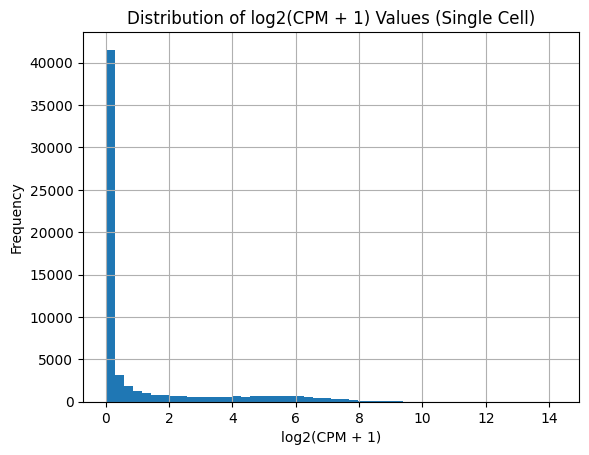

In [62]:
import matplotlib.pyplot as plt
#now let's plot similar to before
plt.hist(target_values, bins=50)
plt.xlabel('log2(CPM + 1)')
plt.ylabel('Frequency')
plt.title('Distribution of log2(CPM + 1) Values (Single Cell)')
plt.grid(True)

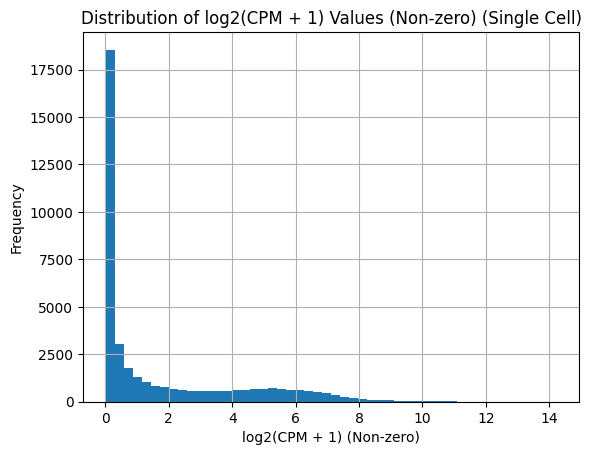

In [61]:
#and we can exxclude the 0s
log2_nonzero_cpm = target_values[target_values > 0]
plt.hist(log2_nonzero_cpm, bins=50)
plt.xlabel('log2(CPM + 1) (Non-zero)')
plt.ylabel('Frequency')
plt.title('Distribution of log2(CPM + 1) Values (Non-zero) (Single Cell)')
plt.grid(True)

In [ ]:
gene_index = adata.var_names_noversion.get_loc(mapped_gene)


62521

In [92]:
sc_dict = final_bulk_dict.copy()
#and set all counts to -1
for gene in sc_dict:
    sc_dict[gene]['counts'] = -1 #so we know it was reassigned
sc_dict

{'ENSG00000186092.7': {'counts': -1, 'tss': 69090, 'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': -1,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': -1,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': -1,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': -1,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': -1,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]},
 'ENSG00000188290.12': {'counts': -1,
  'tss': 1000172,
  'alt_tss': [1000097, 1000172, 999981

In [69]:
len(target_values), len(adata.var_names_noversion) #so we have 62k genes in the adata, and 18k in the bulk dict, so we should have values for all 18k genes in the bulk dict after this loop

(62703, 62703)

In [73]:
name_to_ensembl

{'OR4F5': 'ENSG00000186092.7',
 'OR4F29': 'ENSG00000284733.2',
 'OR4F16': 'ENSG00000284662.2',
 'SAMD11': 'ENSG00000187634.14',
 'NOC2L': 'ENSG00000188976.12',
 'KLHL17': 'ENSG00000187961.16',
 'PLEKHN1': 'ENSG00000187583.12',
 'PERM1': 'ENSG00000187642.11',
 'HES4': 'ENSG00000188290.12',
 'ISG15': 'ENSG00000187608.11',
 'AGRN': 'ENSG00000188157.16',
 'RNF223': 'ENSG00000237330.3',
 'C1orf159': 'ENSG00000131591.19',
 'TTLL10': 'ENSG00000162571.15',
 'TNFRSF18': 'ENSG00000186891.14',
 'TNFRSF4': 'ENSG00000186827.12',
 'SDF4': 'ENSG00000078808.21',
 'B3GALT6': 'ENSG00000176022.7',
 'C1QTNF12': 'ENSG00000184163.3',
 'UBE2J2': 'ENSG00000160087.22',
 'SCNN1D': 'ENSG00000162572.21',
 'ACAP3': 'ENSG00000131584.20',
 'PUSL1': 'ENSG00000169972.14',
 'INTS11': 'ENSG00000127054.23',
 'CPTP': 'ENSG00000224051.8',
 'TAS1R3': 'ENSG00000169962.5',
 'DVL1': 'ENSG00000107404.22',
 'MXRA8': 'ENSG00000162576.18',
 'AURKAIP1': 'ENSG00000175756.15',
 'CCNL2': 'ENSG00000221978.14',
 'MRPL20': 'ENSG000002424

In [ ]:
#when we are getting the gene index, we may have to map from the gencode ensemble id back to the gene symbol. Or better yet is we can define a version of adata.var_names_ensemble that is just the ensemble id which we get by mapping using the gtf dict
# adata.var_names_ensemble_list = []
# for gene in adata.var_names:
#     if gene[:4] == 'ENSG':
#         adata.var_names_ensemble_list.append(gene)
#     else:
#         #try to map to gene name
#         adata.var_names_ensemble_list.append(name_to_ensembl.get(gene, None)) #if it's not found, put None so we know it was unmapped
# #now turn it to the same datatype as the rest
# adata.var_names_ensemble = pd.Index(adata.var_names_ensemble_list)
# adata.var_names_ensemble_list
# # len(adata.var_names_ensemble)

#I don't need lol

['ENSG00000290825.1',
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 'ENSG00000290826',
 None,
 'ENSG00000186092.7',
 'ENSG00000238009',
 'ENSG00000239945',
 None,
 'ENSG00000268903',
 'ENSG00000269981',
 'ENSG00000239906',
 'ENSG00000241860',
 None,
 'ENSG00000241599',
 None,
 None,
 None,
 'ENSG00000228463',
 'ENSG00000286448',
 None,
 'ENSG00000236601',
 'ENSG00000290385',
 None,
 'ENSG00000284733.2',
 'ENSG00000237094',
 None,
 'ENSG00000250575',
 'ENSG00000278757.1',
 'ENSG00000230021',
 'ENSG00000235146',
 None,
 None,
 None,
 'ENSG00000278791',
 None,
 None,
 None,
 None,
 None,
 'ENSG00000284662.2',
 None,
 'ENSG00000291215',
 None,
 'ENSG00000229905',
 'ENSG00000228327',
 None,
 'ENSG00000285268',
 'ENSG00000290784',
 'ENSG00000230092',
 None,
 None,
 None,
 'ENSG00000288531',
 None,
 None,
 'ENSG00000283040',
 'ENSG00000272438',
 'ENSG00000230699',
 'ENSG00000241180',
 None,
 'ENSG00000187634.14',
 'ENSG00000188976.12',
 'ENSG00000187961.16',
 'ENSG00000187583.12',
 'ENSG0

In [113]:
#redefine sc_dict
sc_dict = final_bulk_dict.copy()
#and set all counts to -1
for gene in sc_dict:
    sc_dict[gene]['counts'] = -1 #so we know it was reassigned
# sc_dict

In [114]:
#now assign values to the dict
for gene in sc_dict:
    gene_unversioned = gene.split('.')[0]
    mapped_gene = reverse_mapping.get(gene_unversioned)
    if mapped_gene is None:
        print(f"Gene {gene} not found in adata var names after mapping.")
        break #doesn't break at all, we get a mapping!
    # if mapped_gene is not None:
    #     gene_index = adata.var_names_noversion.get_loc(mapped_gene)
    #     sc_dict[gene]['counts'] = target_values[gene_index]
    # if mapped_gene[:4] == 'ENSG': #if the mapped gene is an ensemble id, we need to get the index using the ensemble var names
    #     mapped_gene = mapped_gene
    # elif mapped_gene in adata.var_names_noversion:
    #     mapped_gene = mapped_gene
    # gene_index = adata.var_names_ensemble.get_loc(mapped_gene)
    #remove the version of mapped gene
    mapped_gene_unversioned = mapped_gene.split('.')[0]
    gene_index = adata.var_names_noversion.get_loc(mapped_gene_unversioned)
    if len(target_values[gene_index].shape) > 0:
        value = target_values[gene_index][0] #if it's an array, get the first value
    else:
        value = target_values[gene_index]
    assert sc_dict[gene]['counts'] == -1, f"Counts for gene {gene} was already assigned, something is wrong."
    sc_dict[gene]['counts'] = float(value)
sc_dict

{'ENSG00000186092.7': {'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.03930346667766571,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]

In [115]:
#and see if any values are -1
missing_values = sum(1 for v in sc_dict.values() if v['counts'] == -1)
print(f"Number of genes in sc_dict with missing counts: {missing_values}")

Number of genes in sc_dict with missing counts: 0


In [ ]:
#ahh perfect, no duplicates and all are assigned!!#ahh perfect, no duplicates and all are assigned!!#ahh perfect, no duplicates and all are assigned!!

In [116]:
#now save both out!
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'w') as f:
    json.dump(final_bulk_dict, f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'w') as f:
    json.dump(sc_dict, f)

In [117]:
#and let's load it in to make sure they're exactly the same
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'r') as f:
    loaded_bulk_dict = json.load(f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'r') as f:
    loaded_sc_dict = json.load(f)
loaded_bulk_dict == final_bulk_dict, loaded_sc_dict == sc_dict #exactly the same!

(True, True)

In [118]:
#now let's see if the distributions are simlar!
bulk_counts = [v['counts'] for v in final_bulk_dict.values()]
sc_counts = [v['counts'] for v in sc_dict.values()]
len(bulk_counts), len(sc_counts) #so we have 18k genes in both, which is perfect for comparison

(18628, 18628)

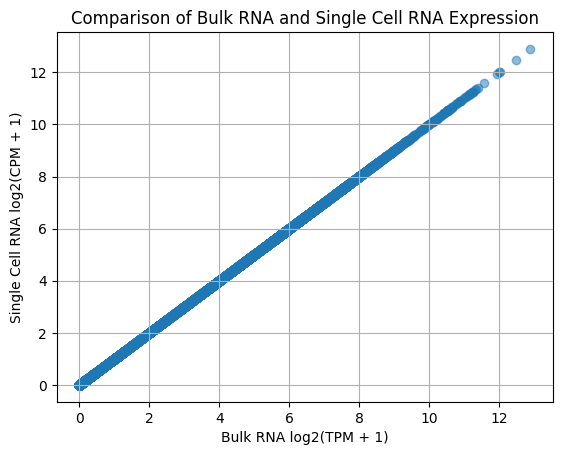

In [119]:
#now let's do some plots
plt.scatter(bulk_counts, sc_counts, alpha=0.5)
plt.xlabel('Bulk RNA log2(TPM + 1)')
plt.ylabel('Single Cell RNA log2(CPM + 1)')
plt.title('Comparison of Bulk RNA and Single Cell RNA Expression')
plt.grid(True)

In [120]:
#ok something is almost definitely wrong?
sc_dict

{'ENSG00000186092.7': {'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.03930346667766571,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]

In [124]:
final_bulk_dict

{'ENSG00000186092.7': {'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634.14': {'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.12': {'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642.11': {'counts': 0.03930346667766571,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982106]

In [123]:
target_values

array([ 0.0315279 ,  0.        ,  2.2055104 , ..., 12.7105465 ,
        0.08509637,  0.84429383], dtype=float32)

In [ ]:
#let's see if it somehow changed the values on accident, load in unfiltered data
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info_unfiltered.json', 'r') as f:
    unfiltered_bulk_dict = json.load(f)
unfiltered_bulk_dict['ENSG00000186092.7'] #yeah it did, the copy didn't work??

{'counts': 0.0, 'tss': 69090, 'alt_tss': [65419]}

In [126]:
#let's redo the filtering and save it out then?
len(not_found), not_found

(117,
 ['ENSG00000175262.15',
  'ENSG00000162522.12',
  'ENSG00000116922.16',
  'ENSG00000186973.12',
  'ENSG00000081870.13',
  'ENSG00000162398.12',
  'ENSG00000162636.17',
  'ENSG00000173947.14',
  'ENSG00000198854.5',
  'ENSG00000000460.18',
  'ENSG00000143633.14',
  'ENSG00000173728.11',
  'ENSG00000150873.13',
  'ENSG00000173557.15',
  'ENSG00000221843.6',
  'ENSG00000177994.16',
  'ENSG00000172073.4',
  'ENSG00000136710.11',
  'ENSG00000196659.10',
  'ENSG00000197557.7',
  'ENSG00000241186.11',
  'ENSG00000236980.10',
  'ENSG00000168273.9',
  'ENSG00000114405.12',
  'ENSG00000214324.5',
  'ENSG00000243449.9',
  'ENSG00000173013.6',
  'ENSG00000154274.16',
  'ENSG00000249693.3',
  'ENSG00000164096.14',
  'ENSG00000145375.10',
  'ENSG00000164123.7',
  'ENSG00000229894.5',
  'ENSG00000205129.10',
  'ENSG00000215217.8',
  'ENSG00000134056.13',
  'ENSG00000113231.14',
  'ENSG00000113391.20',
  'ENSG00000196900.5',
  'ENSG00000221886.5',
  'ENSG00000204661.10',
  'ENSG00000112739.18',


In [128]:
#so filter it
final_bulk_dict = {k: v for k, v in unfiltered_bulk_dict.items() if k not in not_found}
len(final_bulk_dict), final_bulk_dict

(18628,
 {'ENSG00000186092.7': {'counts': 0.0, 'tss': 69090, 'alt_tss': [65419]},
  'ENSG00000187634.14': {'counts': 1.1043366598147355,
   'tss': 925740,
   'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
  'ENSG00000188976.12': {'counts': 6.783325684813521,
   'tss': 959299,
   'alt_tss': [959244,
    959250,
    959251,
    959256,
    959260,
    959262,
    959263,
    959265,
    959266,
    959267,
    959270,
    959271,
    959276,
    959277,
    959278,
    959283,
    959284,
    959285,
    959286,
    959293,
    959300,
    960714]},
  'ENSG00000187961.16': {'counts': 9.189972773359631,
   'tss': 960586,
   'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
  'ENSG00000187583.12': {'counts': 1.5210507369009632,
   'tss': 966496,
   'alt_tss': [966437,
    966502,
    973512,
    966476,
    966510,
    966482,
    966490,
    966492]},
  'ENSG00000187642.11': {'counts': 0.2387868595871165,
   'tss': 982117,
   'alt_tss': [982112,


In [129]:
#and save it out again
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'w') as f:
    json.dump(final_bulk_dict, f)

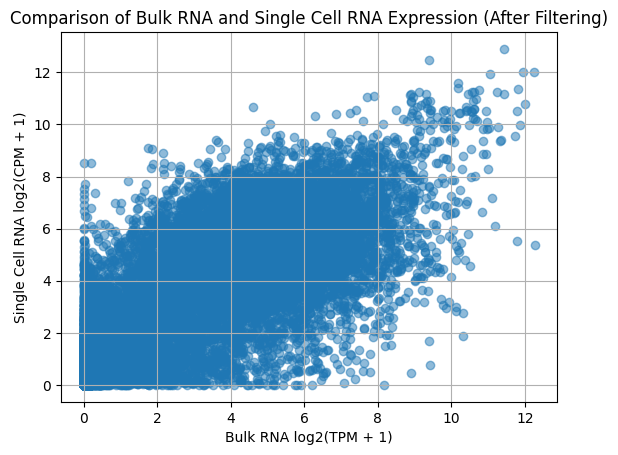

In [130]:
#now let's plot again
bulk_counts = [v['counts'] for v in final_bulk_dict.values()]
sc_counts = [v['counts'] for v in sc_dict.values()]
plt.scatter(bulk_counts, sc_counts, alpha=0.5)
plt.xlabel('Bulk RNA log2(TPM + 1)')
plt.ylabel('Single Cell RNA log2(CPM + 1)')
plt.title('Comparison of Bulk RNA and Single Cell RNA Expression (After Filtering)')
plt.grid(True)

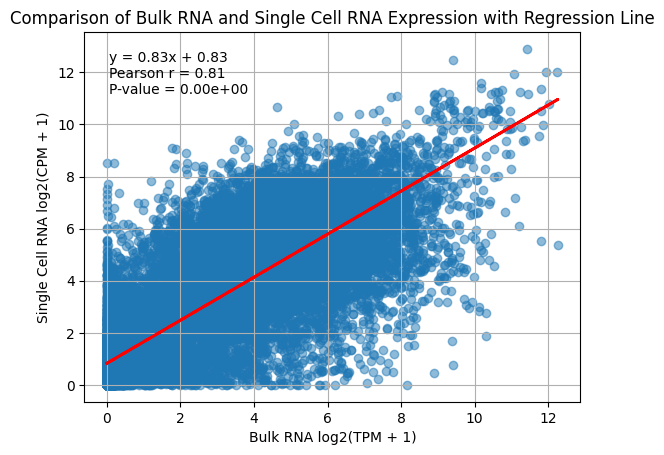

In [136]:
#and let's do a lienar regression to plot it
from sklearn.linear_model import LinearRegression
import numpy as np

# Prepare the data for linear regression
X = np.array(bulk_counts).reshape(-1, 1)
y = np.array(sc_counts)

# Fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Get the regression line
y_pred = model.predict(X)

# Plot the regression line
plt.plot(bulk_counts, y_pred, color='red', linewidth=2)
#and plot the data
plt.scatter(bulk_counts, sc_counts, alpha=0.5)
plt.xlabel('Bulk RNA log2(TPM + 1)')
plt.ylabel('Single Cell RNA log2(CPM + 1)')
plt.title('Comparison of Bulk RNA and Single Cell RNA Expression with Regression Line')
plt.grid(True)

#and put the equation and pearson correlation on the plot
from scipy.stats import pearsonr
# Calculate Pearson correlation coefficient
corr_coef, p_value = pearsonr(bulk_counts, sc_counts)
# Get the regression coefficients
slope = model.coef_[0]
intercept = model.intercept_
# Add the equation and correlation coefficient to the plot
plt.text(0.05, 0.95, f'y = {slope:.2f}x + {intercept:.2f}\nPearson r = {corr_coef:.2f}\nP-value = {p_value:.2e}', 
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')

plt.show()

In [ ]:
#let's see some of the unique values in X matrix from anndata
#wait if all ints, so should the sum values?
#check if raw_pseudobulk_counts are all ints
print(np.all(raw_pseudobulk_counts.astype(int) == raw_pseudobulk_counts)) #so they are all ints, which makes sense because it's a sum of counts. So they are also just raw numbers, so our CPM calculation makes sense!

True


# make it more efficient and ensure correctness

In [ ]:
# adding chromosome
#first write script to recreate both efficiently and review code. Can also use the name given by the tss file to be more efficient in finding the mapping to ensemble ID. Create dict from that!
#this let's us make adata var names with unlabeled ensemble IDs which is what we need? Then we don't really need the gtf...

#TODO add in the loading of the dicts and compare to the recreated ones

#TODO now loop through the tss df and then use that to assign. Make sure set default chrom to None, and then see if any are still None after

#then save them out

#we really should

In [2]:
#load in gtf

#so now we want to create this JSON file, first we need to load gencode info
import re
import json
import pandas as pd
import numpy as np

gtf_path = "/data1/lesliec/sarthak/data/DE_danwei/gencode.v49.annotation.gtf"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chrom", "source", "feature",
        "start", "end", "score",
        "strand", "frame", "attribute"
    ],
)

def get_attr(attr_str, key):
    m = re.search(fr'{key} "([^"]+)"', attr_str)
    return m.group(1) if m else None

for key in ["gene_id", "transcript_id", "gene_type", "gene_name", "transcript_type"]:
    gtf[key] = gtf["attribute"].apply(lambda s, k=key: get_attr(s, k))

gtf_coding = gtf[gtf['gene_type'] == 'protein_coding']
gtf_coding

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
2486,chr1,HAVANA,gene,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; gene_type ""protei...",ENSG00000186092.7,None,protein_coding,OR4F5,None
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2488,chr1,HAVANA,exon,65419,65433,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2489,chr1,HAVANA,exon,65520,65573,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2490,chr1,HAVANA,CDS,65565,65573,.,+,0,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750143,chrM,ENSEMBL,gene,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; gene_type ""protei...",ENSG00000198727.2,None,protein_coding,MT-CYB,None
7750144,chrM,ENSEMBL,transcript,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750145,chrM,ENSEMBL,exon,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750146,chrM,ENSEMBL,CDS,14747,15887,.,+,0,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding


In [ ]:
#first let's do the bulk data

tsv_file = "/data1/lesliec/sarthak/data/DK_zarr/raw_files/ENCFF501IXI.tsv"
# Read the TSV file into a DataFrame
df = pd.read_csv(tsv_file, sep='\t')
df_clean = df[df['gene_id'].str.startswith('ENSG')].reset_index(drop=True)

TSS_bounds_file = "/data1/deyk/extras/CollapsedGeneBounds.hg38.TSS500bp.bed"
tss = pd.read_csv(TSS_bounds_file, sep='\t')

df_clean['counts'] = np.log2(df_clean['TPM'] + 1)
df_clean['gene_id_unversioned'] = df_clean['gene_id'].str.split('.').str[0]  # Remove version number
counts_dict = df_clean.set_index('gene_id_unversioned')['counts'].to_dict()

# 2. Process 'tss' from the tss dataframe
# Add 250 to start and map Ensembl_ID to the new tss
tss['main_tss'] = tss['start'] + 250
tss['Ensembl_ID_unversioned'] = tss['Ensembl_ID'].str.split('.').str[0]  # Remove version number
tss_dict = tss.set_index('Ensembl_ID_unversioned')['main_tss'].to_dict()
chrom_dict = tss.set_index('Ensembl_ID_unversioned')['#chr'].to_dict() #also get chrom info

# 3. Process 'alt_tss' from gtf_coding
# Filter for transcripts to avoid redundant exon/CDS rows
tx_df = gtf_coding[(gtf_coding['feature'] == 'transcript') & 
                   (gtf_coding['transcript_type'] == 'protein_coding')].copy()

# Calculate the actual TSS considering the strand
tx_df['calc_tss'] = np.where(tx_df['strand'] == '+', tx_df['start'], tx_df['end'])

# Group by gene_id, extract unique TSS values using set(), and convert to a list
alt_tss_dict = tx_df.groupby('gene_id')['calc_tss'].apply(lambda x: list(set(x))).to_dict()

# 4. Combine into the final nested dictionary
final_gene_dict = {}

# Use the unique genes from your filtered GTF as the base keys
unique_genes = gtf_coding['gene_id'].dropna().unique()

for gene in unique_genes:
    gene_id = gene.split('.')[0]  # Remove version number if present
    final_gene_dict[gene] = {
        'chrom': chrom_dict.get(gene_id, None), #get chrom info, default to None if not found
        'counts': counts_dict.get(gene_id, -1),  # Defaults to -1 if missing from df_clean
        'tss': tss_dict.get(gene_id, None),       # Defaults to None if missing
        'alt_tss': alt_tss_dict.get(gene, [])  # Defaults to empty list if missing
    }

In [ ]:
final_gene_dict



{'ENSG00000186092.7': {'chrom': 'chr1',
  'counts': 0.0,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000284733.2': {'chrom': None,
  'counts': 1.8399595874895318,
  'tss': None,
  'alt_tss': [451678]},
 'ENSG00000284662.2': {'chrom': None,
  'counts': 1.8399595874895318,
  'tss': None,
  'alt_tss': [686654]},
 'ENSG00000187634.14': {'chrom': 'chr1',
  'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976.12': {'chrom': 'chr1',
  'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961.16': {'chrom': 'chr1',
  'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583.1

In [ ]:
missing_counts = sum(1 for v in final_gene_dict.values() if v['counts'] == -1)
missing_tss = sum(1 for v in final_gene_dict.values() if v['tss'] is None)
missing_alt_tss = sum(1 for v in final_gene_dict.values() if len(v['alt_tss']) == 0)
missing_chrom = sum(1 for v in final_gene_dict.values() if v['chrom'] is None)
print(f"Number of genes with missing counts: {missing_counts}", f"Number of genes with missing tss: {missing_tss}", f"Number of genes with missing alt_tss: {missing_alt_tss}", f"Number of genes with missing chrom: {missing_chrom}") #of course same as TSS!

Number of genes with missing counts: 255 Number of genes with missing tss: 1311 Number of genes with missing alt_tss: 351 Number of genes with missing chrom: 1311


In [ ]:
final_gene_dict_filtered = {k: v for k, v in final_gene_dict.items() if v['counts'] != -1 and v['tss'] is not None and len(v['alt_tss']) > 0}
len(final_gene_dict_filtered) #same as before!!

18745

In [ ]:
#now let's do the single cell dict

In [9]:
import anndata as ad
import numpy as np

# 1. Load the file (much faster and lighter than import scanpy)
adata = ad.read_h5ad("/data1/deyk/scdata/251110_igvf_k562_multiome/K562_ERR9847049_Multiome.rna.align.kb.hg38.cells_x_genes.total.h5ad")
adata.var_names

Index(['ENSG00000290825.1', 'DDX11L1', 'WASH7P', 'MIR6859-1', 'MIR1302-2HG',
       'MIR1302-2', 'FAM138A', 'OR4G4P', 'ENSG00000290826', 'OR4G11P',
       ...
       'MT-ND4', 'MT-TH', 'MT-TS2', 'MT-TL2', 'MT-ND5', 'MT-ND6', 'MT-TE',
       'MT-CYB', 'MT-TT', 'MT-TP'],
      dtype='object', length=62703)

In [11]:
tss

,#chr,start,end,name,score,strand,Ensembl_ID,gene_type,main_tss,Ensembl_ID_unversioned
0,chr1,35831,36331,FAM138A,0,-,ENSG00000237613,lincRNA,36081,ENSG00000237613
1,chr1,35831,36331,FAM138F,0,-,ENSG00000282591,lincRNA,36081,ENSG00000282591
2,chr1,68840,69340,OR4F5,0,+,ENSG00000186092,protein_coding,69090,ENSG00000186092
3,chr1,817120,817620,FAM87B,0,+,ENSG00000177757,lincRNA,817370,ENSG00000177757
4,chr1,827272,827772,LINC00115,0,-,ENSG00000225880,lincRNA,827522,ENSG00000225880
...,...,...,...,...,...,...,...,...,...,...
20662,chrY,21386110,21386610,PRORY,0,-,ENSG00000183146,protein_coding,21386360,ENSG00000183146
20663,chrY,21594416,21594916,TTTY13,0,-,ENSG00000184991,lincRNA,21594666,ENSG00000184991
20664,chrY,22298626,22299126,TTTY5,0,-,ENSG00000215560,lincRNA,22298876,ENSG00000215560
20665,chrY,23198842,23199342,DAZ1,0,-,ENSG00000188120,protein_coding,23199092,ENSG00000188120


In [13]:
name_to_ensembl = tss.drop_duplicates(subset=['name']).set_index('name')['Ensembl_ID'].to_dict()
len(name_to_ensembl), name_to_ensembl #it is unique

(20667,
 {'FAM138A': 'ENSG00000237613',
  'FAM138F': 'ENSG00000282591',
  'OR4F5': 'ENSG00000186092',
  'FAM87B': 'ENSG00000177757',
  'LINC00115': 'ENSG00000225880',
  'LINC01128': 'ENSG00000228794',
  'FAM41C': 'ENSG00000230368',
  'SAMD11': 'ENSG00000187634',
  'NOC2L': 'ENSG00000188976',
  'KLHL17': 'ENSG00000187961',
  'PLEKHN1': 'ENSG00000187583',
  'PERM1': 'ENSG00000187642',
  'HES4': 'ENSG00000188290',
  'ISG15': 'ENSG00000187608',
  'AGRN': 'ENSG00000188157',
  'RNF223': 'ENSG00000237330',
  'C1orf159': 'ENSG00000131591',
  'LINC01342': 'ENSG00000223823',
  'TTLL10': 'ENSG00000162571',
  'TNFRSF18': 'ENSG00000186891',
  'TNFRSF4': 'ENSG00000186827',
  'SDF4': 'ENSG00000078808',
  'B3GALT6': 'ENSG00000176022',
  'C1QTNF12': 'ENSG00000184163',
  'UBE2J2': 'ENSG00000160087',
  'SCNN1D': 'ENSG00000162572',
  'ACAP3': 'ENSG00000131584',
  'PUSL1': 'ENSG00000169972',
  'INTS11': 'ENSG00000127054',
  'CPTP': 'ENSG00000224051',
  'TAS1R3': 'ENSG00000169962',
  'DVL1': 'ENSG0000010740

In [14]:
#now create an adata.var_names_ensemble by mapping the var names to ensemble ids not using the gtf but using the names in the tss file
name_to_ensembl = tss.drop_duplicates(subset=['name']).set_index('name')['Ensembl_ID'].to_dict()
adata.var_names_ensemble_list = []
for gene in adata.var_names:
    if gene[:4] == 'ENSG':
        adata.var_names_ensemble_list.append(gene.split('.')[0]) #remove version number if it's an ensemble id
    else:
        adata.var_names_ensemble_list.append(name_to_ensembl.get(gene, None)) #if it's not found, put None so we know it was unmapped
adata.var_names_ensemble = pd.Index(adata.var_names_ensemble_list)
adata.var_names_ensemble

Index(['ENSG00000290825',              None,              None,
                    None,              None,              None,
       'ENSG00000237613',              None, 'ENSG00000290826',
                    None,
       ...
                    None,              None,              None,
                    None,              None,              None,
                    None,              None,              None,
                    None],
      dtype='object', length=62703)

In [ ]:
#how many are not none?
num_unmapped = sum(1 for v in adata.var_names_ensemble if v is None)
print(f"Number of genes in adata.var_names that could not be mapped to Ensembl IDs: {num_unmapped}") #actually not bad at all! I think that's the same as before... no it is slightlyy different but it's fine!

Number of genes in adata.var_names that could not be mapped to Ensembl IDs: 20344


In [24]:
adata.var_names_ensemble_list.index('ENSG00000237611')

16185

In [36]:
name_to_ensembl = tx_df.drop_duplicates(subset=['gene_name']).set_index('gene_name')['gene_id'].to_dict()
#remove the version number from the ensemble ids in the mapping
name_to_ensembl = {k: v.split('.')[0] for k, v in name_to_ensembl.items()}
name_to_ensembl

{'OR4F5': 'ENSG00000186092',
 'OR4F29': 'ENSG00000284733',
 'OR4F16': 'ENSG00000284662',
 'SAMD11': 'ENSG00000187634',
 'NOC2L': 'ENSG00000188976',
 'KLHL17': 'ENSG00000187961',
 'PLEKHN1': 'ENSG00000187583',
 'PERM1': 'ENSG00000187642',
 'HES4': 'ENSG00000188290',
 'ISG15': 'ENSG00000187608',
 'AGRN': 'ENSG00000188157',
 'RNF223': 'ENSG00000237330',
 'C1orf159': 'ENSG00000131591',
 'TTLL10': 'ENSG00000162571',
 'TNFRSF18': 'ENSG00000186891',
 'TNFRSF4': 'ENSG00000186827',
 'SDF4': 'ENSG00000078808',
 'B3GALT6': 'ENSG00000176022',
 'C1QTNF12': 'ENSG00000184163',
 'UBE2J2': 'ENSG00000160087',
 'SCNN1D': 'ENSG00000162572',
 'ACAP3': 'ENSG00000131584',
 'PUSL1': 'ENSG00000169972',
 'INTS11': 'ENSG00000127054',
 'CPTP': 'ENSG00000224051',
 'TAS1R3': 'ENSG00000169962',
 'DVL1': 'ENSG00000107404',
 'MXRA8': 'ENSG00000162576',
 'AURKAIP1': 'ENSG00000175756',
 'CCNL2': 'ENSG00000221978',
 'MRPL20': 'ENSG00000242485',
 'ANKRD65': 'ENSG00000235098',
 'TMEM88B': 'ENSG00000205116',
 'VWA1': 'ENSG0

In [37]:
#let's find a more efficient way to map the gtf names to ids. First do the reverse mapping immediately

name_to_ensembl = tx_df.drop_duplicates(subset=['gene_name']).set_index('gene_name')['gene_id'].to_dict()
#remove the version number from the ensemble ids in the mapping
name_to_ensembl = {k: v.split('.')[0] for k, v in name_to_ensembl.items()}
# name_to_ensembl

adata.var_names_ensemble_list = []
for gene in adata.var_names:
    if gene[:4] == 'ENSG':
        adata.var_names_ensemble_list.append(gene.split('.')[0]) #remove version number if it's an ensemble id
    else:
        adata.var_names_ensemble_list.append(name_to_ensembl.get(gene, None)) #if it's not found, put None so we know it was unmapped
adata.var_names_ensemble = pd.Index(adata.var_names_ensemble_list)
adata.var_names_ensemble

Index(['ENSG00000290825',              None,              None,
                    None,              None,              None,
                    None,              None, 'ENSG00000290826',
                    None,
       ...
       'ENSG00000198886',              None,              None,
                    None, 'ENSG00000198786', 'ENSG00000198695',
                    None, 'ENSG00000198727',              None,
                    None],
      dtype='object', length=62703)

In [ ]:
var_names_set = set(adata.var_names_ensemble)
final_bulk_dict = {}
for k,v in final_gene_dict_filtered.items():
    k = k.split('.')[0] #remove version number
    if k in var_names_set:
        final_bulk_dict[k] = v
len(final_bulk_dict)
#yes this is the number we exxpected!!

18628

In [39]:
#let's now do a deep copy
import copy
sc_dict = copy.deepcopy(final_bulk_dict)
sc_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': 0.0,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': 1.5210507369009632,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642': {'chrom': 'chr1',
  'counts': 0.23878685958711648,
  'tss': 9

In [43]:
#first replace all the values with -1
for gene in sc_dict:
    sc_dict[gene]['counts'] = -1
sc_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': -1,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': -1,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': -1,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': -1,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': -1,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642': {'chrom': 'chr1',
  'counts': -1,
  'tss': 982117,
  'alt_tss': [982112, 982117, 981801, 982093, 982099, 982133, 982134, 982

In [41]:
#ensure bulk dict isn't affected
final_bulk_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': 0.0,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': 1.1043366598147355,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': 6.783325684813521,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': 9.189972773359631,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': 1.5210507369009632,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642': {'chrom': 'chr1',
  'counts': 0.23878685958711648,
  'tss': 9

In [44]:
#now replace with the sc values

raw_pseudobulk_counts = np.array(adata.X.sum(axis=0)).flatten()

# 4. Normalize to CPM (Counts Per Million)
total_umis = raw_pseudobulk_counts.sum()
cpm = (raw_pseudobulk_counts / total_umis) * 1_000_000

# 5. Log2 transform (adding 1 to avoid log(0))
target_values = np.log2(cpm + 1)

for gene in sc_dict:
    gene = gene.split('.')[0] #remove version number
    gene_index = adata.var_names_ensemble.get_loc(gene)

    if len(target_values[gene_index].shape) > 0:
        value = target_values[gene_index][0] #if it's an array, get the first value
    else:
        value = target_values[gene_index]
    assert sc_dict[gene]['counts'] == -1, f"Counts for gene {gene} was already assigned, something is wrong."
    sc_dict[gene]['counts'] = float(value)

sc_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419]},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150]},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714]},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599]},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492]},
 'ENSG00000187642': {'chrom': 'chr1',
  'counts': 0.0393034666776657

In [45]:
#ensure none of it is -1
missing_values = sum(1 for v in sc_dict.values() if v['counts'] == -1)
print(f"Number of genes in sc_dict with missing counts: {missing_values}") #perfect

Number of genes in sc_dict with missing counts: 0


In [46]:
#now let's ensure values are the same with these and the loaded dicts

with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'r') as f:
    loaded_bulk_dict = json.load(f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'r') as f:
    loaded_sc_dict = json.load(f)
    
print(len(loaded_bulk_dict), len(final_bulk_dict), len(loaded_sc_dict), len(sc_dict))

18628 18628 18628 18628


In [50]:
#ensure the keys are the same
print(set(loaded_bulk_dict.keys()) == set(final_bulk_dict.keys())) #perfect
print(set(loaded_sc_dict.keys()) == set(sc_dict.keys())) #perfect
print(set(loaded_bulk_dict.keys()) == set(loaded_sc_dict.keys())) #perfect
print(set(final_bulk_dict.keys()) == set(sc_dict.keys())) #perfect

False
False
True
True


In [ ]:
set(sc_dict.keys()) #ahh so we moved to a version where the keys are the unversioned ensemble ids which I think is probably better??

{'ENSG00000182180',
 'ENSG00000078674',
 'ENSG00000109111',
 'ENSG00000170634',
 'ENSG00000123500',
 'ENSG00000139636',
 'ENSG00000168497',
 'ENSG00000189420',
 'ENSG00000155966',
 'ENSG00000142669',
 'ENSG00000152749',
 'ENSG00000125826',
 'ENSG00000256683',
 'ENSG00000136807',
 'ENSG00000141314',
 'ENSG00000166002',
 'ENSG00000140905',
 'ENSG00000104969',
 'ENSG00000160218',
 'ENSG00000153989',
 'ENSG00000146733',
 'ENSG00000105810',
 'ENSG00000143995',
 'ENSG00000137434',
 'ENSG00000188649',
 'ENSG00000116497',
 'ENSG00000179943',
 'ENSG00000113492',
 'ENSG00000145708',
 'ENSG00000131096',
 'ENSG00000073754',
 'ENSG00000112038',
 'ENSG00000154957',
 'ENSG00000183303',
 'ENSG00000166477',
 'ENSG00000101197',
 'ENSG00000204673',
 'ENSG00000135801',
 'ENSG00000173762',
 'ENSG00000104812',
 'ENSG00000260097',
 'ENSG00000116237',
 'ENSG00000214193',
 'ENSG00000165059',
 'ENSG00000122779',
 'ENSG00000168907',
 'ENSG00000136040',
 'ENSG00000185933',
 'ENSG00000061337',
 'ENSG00000124215',


In [54]:
for gene in loaded_bulk_dict:
    gene_unversioned = gene.split('.')[0]
    #ensure that the gene is in the new dicts
    assert gene_unversioned in sc_dict, f"Gene {gene} from loaded_bulk_dict not found in sc_dict"
    assert gene_unversioned in final_bulk_dict, f"Gene {gene} from loaded_bulk_dict not found in final_bulk_dict"
    
    #ensure that the values are the same for bulk
    assert np.isclose(loaded_bulk_dict[gene]['counts'], final_bulk_dict[gene_unversioned]['counts'], atol=1e-6, rtol=1e-6), f"Counts for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"
    assert loaded_bulk_dict[gene]['tss'] == final_bulk_dict[gene_unversioned]['tss'], f"TSS for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"
    assert loaded_bulk_dict[gene]['alt_tss'] == final_bulk_dict[gene_unversioned]['alt_tss'], f"Alt TSS for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"

    #ensure values are the same for sc
    assert np.isclose(loaded_sc_dict[gene]['counts'], sc_dict[gene_unversioned]['counts'], atol=1e-6, rtol=1e-6), f"Counts for gene {gene} do not match between loaded_sc_dict and sc_dict"
    assert loaded_sc_dict[gene]['tss'] == sc_dict[gene_unversioned]['tss'], f"TSS for gene {gene} do not match between loaded_sc_dict and sc_dict"
    assert loaded_sc_dict[gene]['alt_tss'] == sc_dict[gene_unversioned]['alt_tss'], f"Alt TSS for gene {gene} do not match between loaded_sc_dict   and sc_dict"

In [ ]:
#we can see some minor differences, so do np.isclose

(0.2387868595871165, 0.23878685958711648)

In [55]:
#now save it out

with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'w') as f:
    json.dump(final_bulk_dict, f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'w') as f:
    json.dump(sc_dict, f)

# redo one last time and save strand information

In [1]:
#load in gtf

#so now we want to create this JSON file, first we need to load gencode info
import re
import json
import pandas as pd
import numpy as np

gtf_path = "/data1/lesliec/sarthak/data/DE_danwei/gencode.v49.annotation.gtf"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chrom", "source", "feature",
        "start", "end", "score",
        "strand", "frame", "attribute"
    ],
)

def get_attr(attr_str, key):
    m = re.search(fr'{key} "([^"]+)"', attr_str)
    return m.group(1) if m else None

for key in ["gene_id", "transcript_id", "gene_type", "gene_name", "transcript_type"]:
    gtf[key] = gtf["attribute"].apply(lambda s, k=key: get_attr(s, k))

gtf_coding = gtf[gtf['gene_type'] == 'protein_coding']
gtf_coding

,chrom,source,feature,start,end,score,strand,frame,attribute,gene_id,transcript_id,gene_type,gene_name,transcript_type
2486,chr1,HAVANA,gene,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; gene_type ""protei...",ENSG00000186092.7,None,protein_coding,OR4F5,None
2487,chr1,HAVANA,transcript,65419,71585,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2488,chr1,HAVANA,exon,65419,65433,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2489,chr1,HAVANA,exon,65520,65573,.,+,.,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
2490,chr1,HAVANA,CDS,65565,65573,.,+,0,"gene_id ""ENSG00000186092.7""; transcript_id ""EN...",ENSG00000186092.7,ENST00000641515.2,protein_coding,OR4F5,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7750143,chrM,ENSEMBL,gene,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; gene_type ""protei...",ENSG00000198727.2,None,protein_coding,MT-CYB,None
7750144,chrM,ENSEMBL,transcript,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750145,chrM,ENSEMBL,exon,14747,15887,.,+,.,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding
7750146,chrM,ENSEMBL,CDS,14747,15887,.,+,0,"gene_id ""ENSG00000198727.2""; transcript_id ""EN...",ENSG00000198727.2,ENST00000361789.2,protein_coding,MT-CYB,protein_coding


In [2]:
#first let's do the bulk data

tsv_file = "/data1/lesliec/sarthak/data/DK_zarr/raw_files/ENCFF501IXI.tsv"
# Read the TSV file into a DataFrame
df = pd.read_csv(tsv_file, sep='\t')
df_clean = df[df['gene_id'].str.startswith('ENSG')].reset_index(drop=True)

TSS_bounds_file = "/data1/deyk/extras/CollapsedGeneBounds.hg38.TSS500bp.bed"
tss = pd.read_csv(TSS_bounds_file, sep='\t')

df_clean['counts'] = np.log2(df_clean['TPM'] + 1)
df_clean['gene_id_unversioned'] = df_clean['gene_id'].str.split('.').str[0]  # Remove version number
counts_dict = df_clean.set_index('gene_id_unversioned')['counts'].to_dict()

# 2. Process 'tss' from the tss dataframe
# Add 250 to start and map Ensembl_ID to the new tss
tss['main_tss'] = tss['start'] + 250
tss['Ensembl_ID_unversioned'] = tss['Ensembl_ID'].str.split('.').str[0]  # Remove version number
tss_dict = tss.set_index('Ensembl_ID_unversioned')['main_tss'].to_dict()
chrom_dict = tss.set_index('Ensembl_ID_unversioned')['#chr'].to_dict() #also get chrom info
strand_dict = tss.set_index('Ensembl_ID_unversioned')['strand'].to_dict() #also get strand info

# 3. Process 'alt_tss' from gtf_coding
# Filter for transcripts to avoid redundant exon/CDS rows
tx_df = gtf_coding[(gtf_coding['feature'] == 'transcript') & 
                   (gtf_coding['transcript_type'] == 'protein_coding')].copy()

# Calculate the actual TSS considering the strand
tx_df['calc_tss'] = np.where(tx_df['strand'] == '+', tx_df['start'], tx_df['end'])

# Group by gene_id, extract unique TSS values using set(), and convert to a list
alt_tss_dict = tx_df.groupby('gene_id')['calc_tss'].apply(lambda x: list(set(x))).to_dict()

# 4. Combine into the final nested dictionary
final_gene_dict = {}

# Use the unique genes from your filtered GTF as the base keys
unique_genes = gtf_coding['gene_id'].dropna().unique()

for gene in unique_genes:
    gene_id = gene.split('.')[0]  # Remove version number if present
    final_gene_dict[gene] = {
        'chrom': chrom_dict.get(gene_id, None), #get chrom info, default to None if not found
        'counts': counts_dict.get(gene_id, -1),  # Defaults to -1 if missing from df_clean
        'tss': tss_dict.get(gene_id, None),       # Defaults to None if missing
        'alt_tss': alt_tss_dict.get(gene, []),  # Defaults to empty list if missing
        'strand': strand_dict.get(gene_id, None) #get strand info, default to None if not found
    }

In [6]:
missing_counts = sum(1 for v in final_gene_dict.values() if v['counts'] == -1)
missing_tss = sum(1 for v in final_gene_dict.values() if v['tss'] is None)
missing_alt_tss = sum(1 for v in final_gene_dict.values() if len(v['alt_tss']) == 0)
missing_chrom = sum(1 for v in final_gene_dict.values() if v['chrom'] is None)
print(f"Number of genes with missing counts: {missing_counts}", f"Number of genes with missing tss: {missing_tss}", f"Number of genes with missing alt_tss: {missing_alt_tss}", f"Number of genes with missing chrom: {missing_chrom}") #of course same as TSS!
final_gene_dict_filtered = {k: v for k, v in final_gene_dict.items() if v['counts'] != -1 and v['tss'] is not None and len(v['alt_tss']) > 0}
len(final_gene_dict_filtered) #same as before!!

Number of genes with missing counts: 255 Number of genes with missing tss: 1311 Number of genes with missing alt_tss: 351 Number of genes with missing chrom: 1311


18745

In [3]:
import anndata as ad
import numpy as np

# 1. Load the file (much faster and lighter than import scanpy)
adata = ad.read_h5ad("/data1/deyk/scdata/251110_igvf_k562_multiome/K562_ERR9847049_Multiome.rna.align.kb.hg38.cells_x_genes.total.h5ad")


In [4]:
name_to_ensembl = tx_df.drop_duplicates(subset=['gene_name']).set_index('gene_name')['gene_id'].to_dict()
#remove the version number from the ensemble ids in the mapping
name_to_ensembl = {k: v.split('.')[0] for k, v in name_to_ensembl.items()}
# name_to_ensembl

adata.var_names_ensemble_list = []
for gene in adata.var_names:
    if gene[:4] == 'ENSG':
        adata.var_names_ensemble_list.append(gene.split('.')[0]) #remove version number if it's an ensemble id
    else:
        adata.var_names_ensemble_list.append(name_to_ensembl.get(gene, None)) #if it's not found, put None so we know it was unmapped
adata.var_names_ensemble = pd.Index(adata.var_names_ensemble_list)

In [7]:
var_names_set = set(adata.var_names_ensemble)
final_bulk_dict = {}
for k,v in final_gene_dict_filtered.items():
    k = k.split('.')[0] #remove version number
    if k in var_names_set:
        final_bulk_dict[k] = v
len(final_bulk_dict)

18628

In [8]:
import copy
sc_dict = copy.deepcopy(final_bulk_dict)

for gene in sc_dict:
    sc_dict[gene]['counts'] = -1
    
raw_pseudobulk_counts = np.array(adata.X.sum(axis=0)).flatten()

# 4. Normalize to CPM (Counts Per Million)
total_umis = raw_pseudobulk_counts.sum()
cpm = (raw_pseudobulk_counts / total_umis) * 1_000_000

# 5. Log2 transform (adding 1 to avoid log(0))
target_values = np.log2(cpm + 1)

for gene in sc_dict:
    gene = gene.split('.')[0] #remove version number
    gene_index = adata.var_names_ensemble.get_loc(gene)

    if len(target_values[gene_index].shape) > 0:
        value = target_values[gene_index][0] #if it's an array, get the first value
    else:
        value = target_values[gene_index]
    assert sc_dict[gene]['counts'] == -1, f"Counts for gene {gene} was already assigned, something is wrong."
    sc_dict[gene]['counts'] = float(value)

sc_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419],
  'strand': '+'},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150],
  'strand': '+'},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714],
  'strand': '-'},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599],
  'strand': '+'},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492],
 

In [9]:
missing_values = sum(1 for v in sc_dict.values() if v['counts'] == -1)
print(f"Number of genes in sc_dict with missing counts: {missing_values}") #perfect

Number of genes in sc_dict with missing counts: 0


In [10]:
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'r') as f:
    loaded_bulk_dict = json.load(f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'r') as f:
    loaded_sc_dict = json.load(f)
    
print(len(loaded_bulk_dict), len(final_bulk_dict), len(loaded_sc_dict), len(sc_dict))

18628 18628 18628 18628


In [11]:
for gene in loaded_bulk_dict:
    gene_unversioned = gene.split('.')[0]
    #ensure that the gene is in the new dicts
    assert gene_unversioned in sc_dict, f"Gene {gene} from loaded_bulk_dict not found in sc_dict"
    assert gene_unversioned in final_bulk_dict, f"Gene {gene} from loaded_bulk_dict not found in final_bulk_dict"
    
    #ensure that the values are the same for bulk
    assert np.isclose(loaded_bulk_dict[gene]['counts'], final_bulk_dict[gene_unversioned]['counts'], atol=1e-6, rtol=1e-6), f"Counts for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"
    assert loaded_bulk_dict[gene]['tss'] == final_bulk_dict[gene_unversioned]['tss'], f"TSS for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"
    assert loaded_bulk_dict[gene]['alt_tss'] == final_bulk_dict[gene_unversioned]['alt_tss'], f"Alt TSS for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"
    assert loaded_bulk_dict[gene]['chrom'] == final_bulk_dict[gene_unversioned]['chrom'], f"Chromosome for gene {gene} do not match between loaded_bulk_dict and final_bulk_dict"

    #ensure values are the same for sc
    assert np.isclose(loaded_sc_dict[gene]['counts'], sc_dict[gene_unversioned]['counts'], atol=1e-6, rtol=1e-6), f"Counts for gene {gene} do not match between loaded_sc_dict and sc_dict"
    assert loaded_sc_dict[gene]['tss'] == sc_dict[gene_unversioned]['tss'], f"TSS for gene {gene} do not match between loaded_sc_dict and sc_dict"
    assert loaded_sc_dict[gene]['alt_tss'] == sc_dict[gene_unversioned]['alt_tss'], f"Alt TSS for gene {gene} do not match between loaded_sc_dict   and sc_dict"
    assert loaded_sc_dict[gene]['chrom'] == sc_dict[gene_unversioned]['chrom'], f"Chromosome for gene {gene} do not match between loaded_sc_dict and sc_dict"

In [12]:
#yup seems good, let's save it
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'w') as f:
    json.dump(final_bulk_dict, f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'w') as f:
    json.dump(sc_dict, f)

In [14]:
sc_dict

{'ENSG00000186092': {'chrom': 'chr1',
  'counts': 0.6085572242736816,
  'tss': 69090,
  'alt_tss': [65419],
  'strand': '+'},
 'ENSG00000187634': {'chrom': 'chr1',
  'counts': 1.5055503845214844,
  'tss': 925740,
  'alt_tss': [925731, 930312, 939275, 923923, 923924, 925942, 925150],
  'strand': '+'},
 'ENSG00000188976': {'chrom': 'chr1',
  'counts': 5.45854377746582,
  'tss': 959299,
  'alt_tss': [959244,
   959250,
   959251,
   959256,
   959260,
   959262,
   959263,
   959265,
   959266,
   959267,
   959270,
   959271,
   959276,
   959277,
   959278,
   959283,
   959284,
   959285,
   959286,
   959293,
   959300,
   960714],
  'strand': '-'},
 'ENSG00000187961': {'chrom': 'chr1',
  'counts': 3.62911319732666,
  'tss': 960586,
  'alt_tss': [960576, 960581, 960584, 960585, 960586, 960595, 960599],
  'strand': '+'},
 'ENSG00000187583': {'chrom': 'chr1',
  'counts': 0.7807775139808655,
  'tss': 966496,
  'alt_tss': [966437, 966502, 973512, 966476, 966510, 966482, 966490, 966492],
 

# one final modification, make a train test split

In [10]:
#save the above as unlabeled and now load them

import json
import pandas as pd

with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info_unlabeled.json', 'r') as f:
    final_bulk_dict = json.load(f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info_unlabeled.json', 'r') as f:
    sc_dict = json.load(f)
    
#now let's do a train test split
# Load bed file: chrom, start, stop, split (ignore fold and number columns)
bed_path = '/data1/lesliec/sarthak/data/DK_zarr/sequences_borzoi_fold3-4.bed'
bed = pd.read_csv(bed_path, sep='\t', header=None, names=['chrom', 'start', 'stop', 'split', 'fold', 'number'])

# Build interval lookup for val and test only (default is train, no need to store those)
from collections import defaultdict
bed_intervals = defaultdict(list)  # chrom -> list of (start, stop, split)
for _, row in bed[bed['split'].isin(['val', 'test'])].iterrows():
    bed_intervals[row['chrom']].append((int(row['start']), int(row['stop']), row['split']))

bed_intervals

defaultdict(list,
            {'chr5': [(41626145, 41822753, 'test'),
              (13736747, 13933355, 'test'),
              (28644473, 28841081, 'test'),
              (19842506, 20039114, 'test'),
              (29726279, 29922887, 'test'),
              (34496060, 34692668, 'test'),
              (100788580, 100985188, 'test'),
              (28841165, 29037773, 'test'),
              (41429453, 41626061, 'test'),
              (37593959, 37790567, 'test'),
              (10442156, 10638764, 'test'),
              (23137097, 23333705, 'test'),
              (102509635, 102706243, 'test'),
              (20678447, 20875055, 'test'),
              (102263770, 102460378, 'test'),
              (99362563, 99559171, 'test'),
              (15900359, 16096967, 'test'),
              (10589675, 10786283, 'test'),
              (32184929, 32381537, 'test'),
              (41970356, 42166964, 'test'),
              (11917346, 12113954, 'test'),
              (21071831, 21268439, 'test'),


In [11]:
def assign_split(chrom, tss):
    """Return the split for a gene based on whether its TSS falls in a val/test interval.
    Defaults to 'train' if no overlap is found. Splits are expected to be unique per TSS.
    """
    if tss is None or chrom is None:
        return 'train'
    for start, stop, split in bed_intervals.get(chrom, []):
        if start <= tss < stop:
            return split
    return 'train'

#let's test this if it makes sense?
bed_intervals['chr5'] #yeah and we just loop through and assign. Should be ok?

[(41626145, 41822753, 'test'),
 (13736747, 13933355, 'test'),
 (28644473, 28841081, 'test'),
 (19842506, 20039114, 'test'),
 (29726279, 29922887, 'test'),
 (34496060, 34692668, 'test'),
 (100788580, 100985188, 'test'),
 (28841165, 29037773, 'test'),
 (41429453, 41626061, 'test'),
 (37593959, 37790567, 'test'),
 (10442156, 10638764, 'test'),
 (23137097, 23333705, 'test'),
 (102509635, 102706243, 'test'),
 (20678447, 20875055, 'test'),
 (102263770, 102460378, 'test'),
 (99362563, 99559171, 'test'),
 (15900359, 16096967, 'test'),
 (10589675, 10786283, 'test'),
 (32184929, 32381537, 'test'),
 (41970356, 42166964, 'test'),
 (11917346, 12113954, 'test'),
 (21071831, 21268439, 'test'),
 (9212831, 9409439, 'test'),
 (11671481, 11868089, 'test'),
 (18809873, 19006481, 'test'),
 (11278097, 11474705, 'test'),
 (11081405, 11278013, 'test'),
 (39610052, 39806660, 'test'),
 (36659672, 36856280, 'test'),
 (102411289, 102607897, 'test'),
 (23776346, 23972954, 'test'),
 (29972144, 30168752, 'test'),
 (

In [12]:
# Assign split based on main TSS overlap with bed intervals.
# Both dicts share identical genes/chrom/tss, so assign once and copy across.
from tqdm import tqdm
from collections import Counter
for gene, info in tqdm(final_bulk_dict.items(), desc="Assigning splits"):
    info['split'] = assign_split(info['chrom'], info['tss'])
    sc_dict[gene]['split'] = info['split']

Assigning splits: 100%|██████████| 18628/18628 [00:00<00:00, 66910.19it/s]


In [ ]:
split_counts = Counter(v['split'] for v in final_bulk_dict.values())
print(f"Split distribution: {dict(split_counts)}")

#ok val was fixed now, it works!

Split distribution: {'train': 14756, 'test': 1838, 'val': 2034}


In [14]:
#now save this out
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_bulk_rna_info.json', 'w') as f:
    json.dump(final_bulk_dict, f)
with open('/data1/lesliec/sarthak/data/DE_danwei/k562_sc_rna_info.json', 'w') as f:
    json.dump(sc_dict, f)


In [ ]:
#wrote all this to a file too!